## 🤖 Complete Plant Simulation Specification: Discrete-Time Open-Loop Asymmetric 4-Omni Robot Model

This cell specifies the comprehensive mathematical framework for the 4-wheel omni-directional mobile robot simulation. The architecture accounts for **asymmetric wheel layouts**, **dynamic multi-axis weight transfer (pitch and roll)**, **disturbanced from real world system vibration and noise** and **non-linear stick-slip traction transitions** derived explicitly for digital execution at a fixed sampling interval $\Delta T$ (or $T_s$).

---
<details>
<summary><b> Open this for the full specification of the simulation equations</b></summary>


### 1. Parameters & Variable Definitions

#### 🛠️ Hardware & Structural Parameters
* $M_r$: Total mass of the robot chassis (kg)
* $J_{zz}$: Rotational mass moment of inertia of the robot around its vertical Z-axis (kg·m²)
* $J_w$: Rotational mass moment of inertia of an individual wheel/rotor assembly (kg·m²)
* $R_b$: Geometric radius of the robot base circle from the Center of Mass (meters)
* $r$: Operating radius of the omni-wheel tires (meters)
* $\alpha_f$: Mounting angle of the front wheels relative to the local $+x_r$-axis (right), measured counter-clockwise (rad)
* $\alpha_b$: Mounting angle of the rear wheels relative to the local $+x_r$-axis (right), measured clockwise (rad)
* $h$: Height of the robot Center of Mass (CoM) above the ground plane (meters)
* $R, L_m$: Armature resistance ($\Omega$) and inductance (H) of individual DC motors
* $K_t, K_b$: Electromechanical torque (Nm/A) and back-EMF (V/(rad/s)) constants
* $C_{rr}$: Floor-tire rolling resistance coefficient
* $\mu_s, \mu_k$: Static and kinetic coefficients of friction between tire rollers and floor

---

### 2. Signal Tracker Definitions

At each sample time step $k$, the discrete simulation cycle processes the following variables:

#### System Inputs
* $\mathbf{V}_k = [V_{1,k}, V_{2,k}, V_{3,k}, V_{4,k}]^\top$: Motor armature terminal voltage commands applied to each wheel (Volts).

#### Tracked Memory Integration States
* $\mathbf{I}_k = [i_{1,k}, i_{2,k}, i_{3,k}, i_{4,k}]^\top$: Motor armature current states (Amperes).
* $\mathbf{\Omega}_k = [\omega_{1,k}, \omega_{2,k}, \omega_{3,k}, \omega_{4,k}]^\top$: Mechanical wheel angular velocity states (rad/s).
* $\mathbf{\dot{X}}_{r,k} = [\dot{x}_{r,k}, \dot{y}_{r,k}, \dot{\theta}_{k}]^\top$: Local robot coordinate chassis velocities, $x_r$ right and $y_r$ forward (m/s, m/s, rad/s).
* $\mathbf{\ddot{X}}_{r,k-1} = [a_{x,r,k-1}, a_{y,r,k-1}, \alpha_{r,k-1}]^\top$: Local chassis accelerations retained from the *previous* time step to decouple normal force weight transfer allocations (m/s², m/s², rad/s²).
* $\mathbf{\dot{X}}_{g,k} = [\dot{x}_{g,k}, \dot{y}_{g,k}, \dot{\theta}_{g,k}]^\top$: Global room frame chassis velocities (m/s, m/s, rad/s).
* $\mathbf{X}_{g,k} = [x_k, y_k, \theta_k]^\top$: Absolute global room frame navigation positions (meters, meters, radians).

#### Plant Observation and Feedback Outputs (Algebraic Trackers)
* $\mathbf{T}_{m,k} = [T_{m,1,k}, T_{m,2,k}, T_{m,3,k}, T_{m,4,k}]^\top$: Instantaneous electromagnetic motor drive torque vector (Nm).
* $\mathbf{F}_{n,k} = [F_{n,1,k}, F_{n,2,k}, F_{n,3,k}, F_{n,4,k}]^\top$: Dynamic normal loading force per wheel including pitch/roll transfer (Newtons).
* $\mathbf{T}_{roll,k} = [T_{roll,1,k}, T_{roll,2,k}, T_{roll,3,k}, T_{roll,4,k}]^\top$: Parasitic floor rolling resistance torques opposing wheel rotation (Nm).
* $\mathbf{F}_k = [F_{1,k}, F_{2,k}, F_{3,k}, F_{4,k}]^\top$: Active non-linear tractive forces transmitted from the floor patch to the robot frame (Newtons).
* $\mathbf{S}_k = [s_{1,k}, s_{2,k}, s_{3,k}, s_{4,k}]^\top$: Boolean wheel traction indicator status vector, where $s_{i,k} = 0$ for Pure Rolling (Sticking) and $s_{i,k} = 1$ for Skidding/Spinout (Slipping).
* $\mathbf{T}_{load, k} = [T_{load,1,k}, T_{load,2,k}, T_{load,3,k}, T_{load,4,k}]^\top$: Mechanical load torque vectors experienced by each motor armature (Nm).
* $\mathbf{X}_{g,k+1} = [x_{k+1}, y_{k+1}, \theta_{k+1}]^\top$: Updated absolute global navigation coordinate profile shifted into the next step.

---

### 3. Kinematic Kinematics Mapping Matrix ($\mathbf{H}$)

The transformation matrix $\mathbf{H}$ projects the rigid chassis velocities into ideal linear speeds parallel to the driving direction of the wheel contact patches. Given the front/back asymmetry ($\alpha_f \neq \alpha_b$), it is defined as:

$$\mathbf{H} = \begin{bmatrix} -\sin(\alpha_f) & \cos(\alpha_f) & R_b \\  -\sin(\alpha_f) & -\cos(\alpha_f) & R_b \\  \sin(\alpha_b) & -\cos(\alpha_b) & R_b \\  \sin(\alpha_b) & \cos(\alpha_b) & R_b \end{bmatrix}$$

$$\mathbf{V}_{wheel, k} = \mathbf{H} \mathbf{\dot{X}}_{r,k}$$


$$
\begin{bmatrix} v_1 \\ v_2 \\ v_3 \\ v_4 \end{bmatrix}_k = H \begin{bmatrix} \dot{x}_r \\ \dot{y}_r \\ \dot{\theta} \end{bmatrix}_k
$$


---

### 4. Sequential Step Execution Flow

1. **Read System Inputs and States**: Load voltage vector and the historical state markers from step k.
2. **Compute Electrical Motor Torque**: Evaluate the gross torque produced by the motor armatures.
3. **Calculate Dynamic Normal Forces**: Apply structural wheelbase configurations and past accelerations to check real-time load distribution.
4. **Contact Mechanics Constraints**: Determine rolling resistance limits, check friction ceilings, identify stick/slip states, and output bounded ground forces.
5. **Chassis Rigid Body Acceleration**: Extract local accelerations through the inverse mass and transposed kinematics matrices.
6. **Velocity Integration and Frame Rotation**: Advance local frame velocities and map them into global room frame velocity space.
7. **Global Position Advancement**: Integrate global velocities to shift the absolute physical coordinate positions.
8. **Back-Projection & Feedback Loop Closure**: Map updated chassis momentum down to wheel components, handle split velocity integrations for spinning wheels, and isolate the output load torque values.


---
### 5. Explicit Discrete-Time Subsystem Equations

#### Step 5.1: Discrete Electrical Motor Current System
The continuous electrical differential equation for a motor is $V(t) = R \cdot i(t) + L_m \frac{di(t)}{dt} + K_b \cdot \omega(t)$. Isolating the current derivative yields $\frac{di(t)}{dt} = \frac{1}{L_m}\left(V(t) - R \cdot i(t) - K_b \cdot \omega(t)\right)$.

Applying the Forward Euler discrete transformation ($\frac{di(t)}{dt} \approx \frac{i_{k+1} - i_k}{dt}$) to all 4 motors simultaneously, the explicit update equation for the current vector is:

$$
\begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_{k+1} = \begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_k + \frac{dt}{L_m} \left( \begin{bmatrix} V_1 \\ V_2 \\ V_3 \\ V_4 \end{bmatrix}_k - R \begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_k - K_b \begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \\ \omega_4 \end{bmatrix}_k \right)
$$

The instantaneous gross electromagnetic torque vector produced by the armatures at time step $k$ maps directly from the current:

$$
\mathbf{T}_{m,k} = \begin{bmatrix} T_{m,1,k} \\ T_{m,2,k} \\ T_{m,3,k} \\ T_{m,4,k} \end{bmatrix} = K_t \begin{bmatrix} i_{1,k} \\ i_{2,k} \\ i_{3,k} \\ i_{4,k} \end{bmatrix}
$$

#### Step 5.2: Dynamic Normal Force Balance
Extract vehicle geometry parameters relative to the Center of Mass:
$$
x_f = R_b\cos(\alpha_f), \quad x_b = R_b\cos(\alpha_b), \quad \Sigma X^2 = x_f^2 + x_b^2
$$
$$
y_f = R_b\sin(\alpha_f), \quad y_b = R_b\sin(\alpha_b), \quad L = y_f + y_b
$$

Using the historical acceleration vector from the previous time step ($a_{x,r,k-1}, a_{y,r,k-1}$), calculate individual tire normal forces ($F_{n,i,k}$) to prevent algebraic system loops:
$$
F_{n,1,k} = \frac{M_r g y_b}{2L} - \frac{M_r a_{y,r,k-1} h}{2L} - \left( \frac{x_f}{\Sigma X^2} \right) \frac{M_r a_{x,r,k-1} h y_b}{L}
$$
$$
F_{n,2,k} = \frac{M_r g y_b}{2L} - \frac{M_r a_{y,r,k-1} h}{2L} + \left( \frac{x_f}{\Sigma X^2} \right) \frac{M_r a_{x,r,k-1} h y_b}{L}
$$
$$
F_{n,3,k} = \frac{M_r g y_f}{2L} + \frac{M_r a_{y,r,k-1} h}{2L} + \left( \frac{x_b}{\Sigma X^2} \right) \frac{M_r a_{x,r,k-1} h y_f}{L}
$$
$$
F_{n,4,k} = \frac{M_r g y_f}{2L} + \frac{M_r a_{y,r,k-1} h}{2L} - \left( \frac{x_b}{\Sigma X^2} \right) \frac{M_r a_{x,r,k-1} h y_f}{L}
$$

#### Step 5.3: Non-Linear Contact Patch Friction Model
For each wheel $i$, calculate internal rolling drag and evaluate floor adhesion boundaries:
$$
T_{roll, i,k} = \text{sign}(\omega_{i,k}) \cdot C_{rr} \cdot F_{n,i,k} \cdot r
$$
$$
F_{req, i,k} = \frac{T_{m,i,k} - T_{roll,i,k}}{r}
$$
$$
F_{max, s, i,k} = \mu_s \cdot F_{n,i,k}
$$

The net ground force vector transmitted back into the chassis acceleration equations ($\mathbf{F}_k = [F_{1,k}, F_{2,k}, F_{3,k}, F_{4,k}]^\top$) is computed conditionally based on wheel slip state:
$$
F_{i,k} = \begin{cases} 
F_{req, i,k} & \text{if } |F_{req, i,k}| \le F_{max, s, i,k} \quad \text{(Sticking / Pure Rolling)} \\ 
\text{sign}(F_{req, i,k}) \cdot \mu_k \cdot F_{n,i,k} & \text{if } |F_{req, i,k}| > F_{max, s, i,k} \quad \text{(Slipping / Spinout)} 
\end{cases}
$$

#### Step 5.4: Chassis Frame Mechanical Kinetics
Calculate multi-axis robot-frame accelerations by combining the horizontal forces through the transposed kinematics configuration matrix $H^\top$:
$$
\begin{bmatrix} a_{x,r,k} \\ a_{y,r,k} \\ \alpha_{r,k} \end{bmatrix} = \begin{bmatrix} \frac{1}{M_r} & 0 & 0 \\ 0 & \frac{1}{M_r} & 0 \\ 0 & 0 & \frac{1}{J_{zz}} \end{bmatrix} H^\top \begin{bmatrix} F_{1,k} \\ F_{2,k} \\ F_{3,k} \\ F_{4,k} \end{bmatrix}
$$

#### Step 5.5: Discrete Integration and Frame Transfer Pipeline
Advance local vehicle frame velocities using standard Forward Euler steps across sample time $dt$:
$$
\dot{x}_{r,k+1} = \dot{x}_{r,k} + dt \cdot a_{x,r,k}
$$
$$
\dot{y}_{r,k+1} = \dot{y}_{r,k} + dt \cdot a_{y,r,k}
$$
$$
\dot{\theta}_{k+1} = \dot{\theta}_{k} + dt \cdot \alpha_{r,k}
$$

Transform local velocities into stationary global room velocities via the current heading parameter angle $\theta_k$:
$$
\dot{x}_{g,k+1} = \dot{x}_{r,k+1}\cos(\theta_k) - \dot{y}_{r,k+1}\sin(\theta_k)
$$
$$
\dot{y}_{g,k+1} = \dot{x}_{r,k+1}\sin(\theta_k) + \dot{y}_{r,k+1}\cos(\theta_k)
$$

Increment absolute spatial positions:
$$
x_{k+1} = x_k + dt \cdot \dot{x}_{g,k+1}
$$
$$
y_{k+1} = y_k + dt \cdot \dot{y}_{g,k+1}
$$
$$
\theta_{k+1} = \theta_k + dt \cdot \dot{\theta}_{k+1}
$$

#### Step 5.6: Mechanical Re-coupling and Dynamic Load Torque Calculations
To map the floor interaction directly back to the motor mechanical velocity derivatives, project the target chassis speeds onto the wheels using the kinematic configuration matrix:
$$
\begin{bmatrix} v_{1,k+1} \\ v_{2,k+1} \\ v_{3,k+1} \\ v_{4,k+1} \end{bmatrix} = H \begin{bmatrix} \dot{x}_{r,k+1} \\ \dot{y}_{r,k+1} \\ \dot{\theta}_{k+1} \end{bmatrix}
$$

The mathematical definition of the output resistance torque variable $T_{load,i,k}$ changes depending on the wheel's slip condition. Evaluating the continuous torque unbalance ($T_m - T_{load} = J_w \frac{d\omega}{dt}$) via Forward Euler integration ($\omega_{k+1} = \omega_k + dt \cdot \frac{d\omega}{dt}$), the loop re-couples states under split rules:

* **Condition A: If Wheel $i$ is Sticking (Pure Rolling)**
  The ground provides the exact tracking reaction required to shift the total vehicle mass, forcing the wheel's angular speed to lock directly to the robot's momentum constraints:
  $$
  \omega_{i,k+1} = \frac{v_{i,k+1}}{r}
  $$
  $$
  T_{load, i,k} = (F_{i,k} \cdot r) + T_{roll,i,k} = (F_{req,i,k} \cdot r) + T_{roll,i,k} = T_{m,i,k}
  $$

* **Condition B: If Wheel $i$ is Slipping (Spinout)**
  Traction limits are broken, decoupling the wheel rotation from the vehicle body. The floor force clamps at the kinetic sliding limit, meaning the excess torque unbalance drives the acceleration of the independent wheel/motor assembly inertia ($J_w$):
  $$
  T_{load, i,k} = (\text{sign}(\omega_{i,k}) \cdot \mu_k \cdot F_{n,i,k} \cdot r) + T_{roll,i,k}
  $$
  $$
  \omega_{i,k+1} = \omega_{i,k} + \frac{dt}{J_w} \left( T_{m,i,k} - T_{load,i,k} \right)
  $$

*The computed wheel angular speed vector $\mathbf{\omega}_{k+1}$ is stored in the system history arrays and acts directly as the $K_b \cdot \omega$ Back-EMF source in the upcoming electrical current step ($k+1$), completing the bilateral electromechanical connection loop.*

#### 7. Environmental Disturbances: Structural Vibrational Noise and Inconsistent Friction

To transition this plant from an ideal simulation to an authentic physical environment, we inject two forms of non-deterministic disturbances ($\mathbf{W}_k$) into the state equations at each time step $k$.

$$\begin{array}{rcccl}
[\text{Ideal Normal Force } F_{n, \text{ideal}}] & \longrightarrow & + \text{ Structural Vibration Noise } w_{F} & \longrightarrow & [\text{Perturbed } F_{n,i,k}] \\
[\text{Ideal Friction Coeff } \mu_{\text{nominal}}] & \longrightarrow & + \text{ Spatial Friction Variance } w_{\mu} & \longrightarrow & [\text{Perturbed } \mu_{s,i,k} \ / \ \mu_{k,i,k}]
\end{array}$$



##### Phase 1: High-Frequency Structural Vibrations
Chassis vibrations from gear mesh, floor roughness, and structural flexing cause rapid, high-frequency oscillations in the normal forces ($F_{n,i,k}$). We model this as a zero-mean Gaussian white noise vector added to each wheel's computed normal force:

$$F_{n,i,k,\text{perturbed}} = \max\left(0, \ F_{n,i,k,\text{ideal}} + w_{F,i,k}\right)$$

Where $w_{F,i,k} \sim \mathcal{N}(0, \sigma_V^2)$, and $\sigma_V$ represents the standard deviation of the mechanical vibration amplitude (in Newtons). 
* *Note: The $\max(0, \dots)$ ceiling constraint ensures that severe vibrational spikes cannot physically pull the wheel "through" the floor or simulate a negative normal force.*

##### Phase 2: Inconsistent Spatial Friction Coefficients
Floor conditions like dust patches, scuff marks, or changing floor tile seams cause the local friction constants ($\mu_s, \mu_k$) to vary over time as the robot travels. To model this, we alter the baseline friction coefficients with a bounded random noise profile at each time step:

$$\mu_{s,i,k} = \max\left(0, \ \mu_{s,\text{nominal}} + w_{\mu,i,k}\right)$$
$$\mu_{k,i,k} = \max\left(0, \ \mu_{k,\text{nominal}} + w_{\mu,i,k}\right)$$

Where $w_{\mu,i,k} \sim \mathcal{N}(0, \sigma_{\mu}^2)$, and $\sigma_{\mu}$ governs the inconsistency or roughness of the floor terrain (typically set between `0.02` and `0.08` for realistic surfaces). 

#### Phase 3: Loop Integration Changes
These perturbed values are injected directly into **Step 5.3 (Non-Linear Friction Model)** before evaluating the stick-slip conditional boundary:

$$F_{max, s, i, k} = \mu_{s,i,k} \cdot F_{n,i,k,\text{perturbed}}$$
$$T_{roll, i, k} = \text{sign}(\omega_{i,k}) \cdot C_{rr} \cdot F_{n,i,k,\text{perturbed}} \cdot r$$

If a wheel slips (**Condition B**), the kinetic ground force clamp utilizes the perturbed parameters dynamically:

$$T_{load, i, k} = \left(\text{sign}(F_{req,i,k}) \cdot \mu_{k,i,k} \cdot F_{n,i,k,\text{perturbed}} \cdot r\right) + T_{roll,i,k}$$

* **Simulation Insight:** Adding these perturbations will cause your motor currents ($i_k$) and wheel loads ($T_{load}$) to experience micro-spikes. This accurately simulates real-world conditions where a wheel may momentarily break traction due to a vibration spike or a low-friction spot on the floor, allowing you to rigorously test the resilience of outer control loops.

<details>

---
<details>
<summary><b> Open this for simulation flowchart </b></summary>



```text
==================================================
        SIMULATION STATE DATA (STEP K)
==================================================
 [Inputs] -> Voltages Vector V_1..4
 [Memory] -> Current i_k, Wheel Speeds omega_k
 [Memory] -> Local Chassis Speeds & Past Accel
 [Memory] -> Global Coordinates [x, y, theta]_k
==================================================
                        |
                        v
         +------------------------------+
         |   1. ELECTRICAL SUBSYSTEM    |
         | - Calculate Back-EMF         |
         | - Integrate Armature Current |
         | - Output Electromagnetic T   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    2. STRUCTURAL LOADING     |
         | - Compute Asymmetric Static  |
         | - Shift Load via Past Accel  |
         | - Inject Noise (w_F, w_mu)   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    3. CONTACT INTERFACE      |
         | - Check Friction Threshold   |
         | - Compute Rolling Resistance |
         +------------------------------+
                        |
                        v
              Is |F_req| > F_max ?
             /                  \
     (No)   /                    \   (Yes)
           v                      v
  +-----------------+    +-----------------+
  | STICKING (S=0)  |    |  SLIPPING (S=1) |
  |  Pure Rolling   |    |  Wheel Spinout  |
  |  F_floor=F_req  |    |  F_floor=F_slip |
  +-----------------+    +-----------------+
           \                      /
            \                    /
             v                  v
         +------------------------------+
         |    4. CHASSIS RIGID BODY     |
         | - Compute Local Accel Vector |
         | - Integrate Local Velocity   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    5. COORDINATE ROTATION    |
         | - Map Local to Global Frame  |
         | - Integrate Global Positions |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |   6. MECHANICAL RE-COUPLING  |
         | - Project Wheel Speed Targets|
         | - Update Mechanical omega    |
         | - Calculate Final Load T_load|
         +------------------------------+
                        |
                        v
==================================================
       SIMULATION OUTPUT TRAJECTORY (K+1)
==================================================
 [Output] -> New Spatial Coordinates [x, y, theta]
 [Output] -> Composite Motor Load Vector T_load
 [Output] -> True Slip Flag Matrix Indicators
==================================================
```

### 📂 Omni Simulation Class Architecture

The `OmniRobotSimulation` class implements a modular, discrete-time physics engine executed at each time step $\Delta T$.

*   **`OmniMotorState`**: Data container that preserves and moves the integrated memory states (currents, wheel speeds, local/global velocities, and positions) from step $k$ to $k+1$.
*   **`__init__`**: Handles parameters, extracts asymmetric chassis dimensions, and pre-builds the mass matrix ($\mathbf{M}$) and its inverse ($\mathbf{M}^{-1}$).
*   **`_build_kinematics_matrix`**: Constructs the asymmetric kinematic velocity projection matrix ($H$) based on mounting angles ($\alpha_f, \alpha_b$).
*   **`compute_electrical_subsystem`**: Calculates back-EMF, updates armature currents ($\mathbf{I}_{k+1}$) via Forward Euler, and returns drive torques ($\mathbf{T}_{m,k}$).
*   **`compute_dynamic_normal_forces`**: Evaluates vertical wheel loads ($\mathbf{F}_{n,k}$) by combining static splits, past-acceleration pitch/roll shifts, and vibration noise ($w_F$).
*   **`compute_contact_friction_interface`**: Evaluates stick-slip thresholds with floor friction noise ($w_\mu$). Determines if wheels are Sticking or Slipping, updates traction flags ($\mathbf{S}_k$), and outputs floor reaction forces.
*   **`advance_chassis_kinetics`**: Computes chassis rigid body acceleration ($\mathbf{M}^{-1}H^\top\mathbf{F}_k$), integrates local frame velocities, rotates vectors via $R(\theta)$, and advances global coordinates.
*   **`step`**: Master loop execution engine. Coordinates all functions sequentially, resolves independent rotor spinout integrations ($J_w$) for slipping wheels, and outputs step states alongside data logging tracking metrics ($T_{load}$).


In [1]:
import numpy as np

class OmniMotorState:
    """
    Data container to log and preserve the electromechanical system states 
    at any discrete time step k.
    """
    def __init__(self):
        # Memory Integration States (Differential Cores)
        self.I = np.zeros(4)            # Armature currents [i1, i2, i3, i4] (A)
        self.omega = np.zeros(4)        # Wheel angular velocities [w1, w2, w3, w4] (rad/s)
        self.v_local = np.zeros(3)      # Local chassis velocities [x_dot (right), y_dot (forward), theta_dot] (m/s, rad/s)
        self.a_local_past = np.zeros(3) # Historical chassis accelerations from step k-1 (m/s^2, rad/s^2)
        self.v_global = np.zeros(3)     # Global velocities [x_dot_g, y_dot_g, theta_dot_g] (m/s, rad/s)
        self.pos_global = np.zeros(3)   # Global coordinates [x, y, theta] (m, rad)
        
        # Tracked Logical Status Vector 
        self.S = np.zeros(4, dtype=bool) # Traction flags (False=Sticking, True=Slipping)


class OmniRobotSimulation:
    """
    Physics engine plant managing an asymmetric 4-Omni wheel robot model
    with dynamic weight transfer and non-linear stick-slip floor friction boundaries.
    """
    def __init__(self, params: dict,random_seed: int = 42):
        """
        Initializes hardware constants, geometric parameters, and noise variances.
        """
        self.p = params
        self.dt = params['dt']
        
        # Pre-compute fixed kinematic tracking matrix (H) based on alpha_f and alpha_b
        self.H = self._build_kinematics_matrix()

        # Instantiate a dedicated, isolated random number generator state for this plant
        self.rng = np.random.default_rng(seed=random_seed)

        # --- BUILD THE MASS / INERTIA MATRIX (M) ---
        self.M = np.array([
            [self.p['Mr'], 0.0,           0.0],          # Mass acting on X acceleration
            [0.0,          self.p['Mr'],  0.0],          # Mass acting on Y acceleration
            [0.0,          0.0,           self.p['Jzz']] # Rotational inertia acting on Alpha
        ])
        
        # Pre-compute the Inverse Mass Matrix (M_inv) for high efficiency in step calls
        self.M_inv = np.linalg.inv(self.M)
        
        # Structural wheelbase lengths for weight distribution balances
        self.x_f = self.p['Rb'] * np.cos(self.p['alpha_f'])
        self.x_b = self.p['Rb'] * np.cos(self.p['alpha_b'])
        self.y_f = self.p['Rb'] * np.sin(self.p['alpha_f'])
        self.y_b = self.p['Rb'] * np.sin(self.p['alpha_b'])
        self.L = self.y_f + self.y_b
        self.sum_X2 = (self.x_f**2) + (self.x_b**2)

    def _build_kinematics_matrix(self) -> np.ndarray:
        """Constructs the exact asymmetric velocity projection transformation matrix H."""
        af = self.p['alpha_f']
        ab = self.p['alpha_b']
        Rb = self.p['Rb']
        return np.array([
            [-np.sin(af),  np.cos(af), Rb],  # Wheel 1: Front Right
            [-np.sin(af), -np.cos(af), Rb],  # Wheel 2: Front Left
            [ np.sin(ab), -np.cos(ab), Rb],  # Wheel 3: Rear Left
            [ np.sin(ab),  np.cos(ab), Rb]   # Wheel 4: Rear Right
        ])

    def compute_electrical_subsystem(self, state: OmniMotorState, V_input: np.ndarray) -> np.ndarray:
        """
        Calculates Step 5.1 & 5.7: Advances the motor armature currents using 
        Forward Euler discrete integration and maps them to gross electromagnetic torques.
        
        Parameters:
            state (OmniMotorState): Current step k state configuration
            V_input (np.ndarray): Voltage control inputs vector [V1, V2, V3, V4] (Volts)
            
        Returns:
            T_m (np.ndarray): Gross electromagnetic drive torque vector [T_m1, T_m2, T_m3, T_m4] (Nm)
        """
        # Read parameters for clean vector readability
        Lm = self.p['Lm']
        R = self.p['R']
        Kb = self.p['Kb']
        Kt = self.p['Kt']
        
        # Calculate Back-EMF vector for step k: v_b = Kb * omega
        v_b = Kb * state.omega
        
        # Discrete electrical derivative update: di/dt = (V - R*i - v_b) / Lm
        di_dt = (V_input - R * state.I - v_b) / Lm
        
        # Advance the core electrical state to step k+1 using Forward Euler
        state.I_next = state.I + self.dt * di_dt  # Stored to pass to the next state container later
        
        # Instantaneous drive torque mapping vector generated by step k currents
        T_m = Kt * state.I
        return T_m

    def compute_dynamic_normal_forces(self, state: OmniMotorState) -> np.ndarray:
        """
        Calculates Step 5.2: Determines the vertical load profile for each wheel 
        by balancing static weight distributions with dynamic multi-axis pitch/roll 
        inertial moments, plus random high-frequency structural vibration noise.
        
        Parameters:
            state (OmniMotorState): System states containing historical accelerations (state.a_local_past)
            
        Returns:
            F_n (np.ndarray): Perturbed, non-negative normal loading forces vector [F_n1, F_n2, F_n3, F_n4] (N)
        """
        # Extract constants and pre-calculated geometry metrics
        Mr = self.p['Mr']
        g = 9.81
        h = self.p['h']
        L = self.L
        x_f = self.x_f
        x_b = self.x_b
        y_f = self.y_f
        y_b = self.y_b
        sum_X2 = self.sum_X2
        sigma_V = self.p['sigma_V']
        
        # Extract previous acceleration elements to sever the algebraic force-loop dependency
        ax_past = state.a_local_past[0]
        ay_past = state.a_local_past[1]
        
        # 1. Base Static Distribution Components (Front vs Rear Pair Asymmetry)
        F_n_front_static = (Mr * g * y_b) / (2.0 * L)
        F_n_rear_static  = (Mr * g * y_f) / (2.0 * L)
        
        # 2. Longitudinal Weight Shift Component (Pitch due to forward/backward acceleration)
        delta_Fn_y = (Mr * ay_past * h) / (2.0 * L)
        
        # 3. Asymmetric Lateral Weight Shift Scale Elements (Roll due to strafe accelerations)
        # Note: Roll stiffness causes the wider axle to absorb more lateral tipping moment
        lateral_moment_scale = (Mr * ax_past * h) / L
        delta_Fn_x_front = (x_f / sum_X2) * lateral_moment_scale * y_b
        delta_Fn_x_rear  = (x_b / sum_X2) * lateral_moment_scale * y_f
        
        # 4. Generate High-Frequency Structural Vibration Noise Vectors
        w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
        
        # 5. Compile the Superimposed Linear Array Configurations
        F_n = np.zeros(4)
        F_n[0] = F_n_front_static - delta_Fn_y - delta_Fn_x_front + w_F[0] # Wheel 1: Front Right
        F_n[1] = F_n_front_static - delta_Fn_y + delta_Fn_x_front + w_F[1] # Wheel 2: Front Left
        F_n[2] = F_n_rear_static  + delta_Fn_y + delta_Fn_x_rear  + w_F[2] # Wheel 3: Rear Left
        F_n[3] = F_n_rear_static  + delta_Fn_y - delta_Fn_x_rear  + w_F[3] # Wheel 4: Rear Right
        
        # Physical Guard: Wheels cannot experience negative loading forces (clamped to floor plane separation limit)
        F_n = np.maximum(0.0, F_n)
        return F_n


    def compute_contact_friction_interface(self, T_m: np.ndarray, F_n: np.ndarray, state: OmniMotorState) -> tuple:
        """
        Calculates Step 5.3 & 5.6: Evaluates non-linear floor patch stick-slip friction boundaries.
        Accounts for patch-level random friction variations and returns ground reaction forces,
        feedback loads, and updates the boolean slip vector.
        
        Parameters:
            T_m (np.ndarray): Gross electromagnetic drive torque vector [T_m1..T_m4] (Nm)
            F_n (np.ndarray): Perturbed normal force loading vector [F_n1..F_n4] (N)
            state (OmniMotorState): Current step k system tracking states
            
        Returns:
            F_floor (np.ndarray): Active tractive force vector driving vehicle kinetics [F1..F4] (N)
            T_load (np.ndarray): Mechanical resistance torque vector reflected back to armature (Nm)
            S_status (np.ndarray): Boolean wheel status array (False=Sticking, True=Slipping)
        """
        r = self.p['r']
        Crr = self.p['Crr']
        mu_s_nom = self.p['mu_s']
        mu_k_nom = self.p['mu_k']
        sigma_mu = self.p['sigma_mu']
        
        # 1. Generate Non-Deterministic Spatial Friction Noise
        w_mu = self.rng.normal(0.0, sigma_mu, 4) if sigma_mu > 0 else np.zeros(4)
        mu_s = np.maximum(0.0, mu_s_nom + w_mu)
        mu_k = np.maximum(0.0, mu_k_nom + w_mu)
        
        # 2. Calculate Frictional Drag & Ideal Traction Requests
        T_roll = np.sign(state.omega) * Crr * F_n * r
        F_req = (T_m - T_roll) / r
        
        # 3. Calculate Maximum Static Floor Adhesion Ceiling Bounds
        F_max_static = mu_s * F_n
        
        # 4. Evaluate Threshold Conditional Mapping (Vectorized Check)
        S_status = np.abs(F_req) > F_max_static
        
        # 5. Route Forces and Torques based on logical traction state entries
        F_floor = np.zeros(4)
        T_load = np.zeros(4)
        
        for i in range(4):
            if not S_status[i]:  # Condition A: Sticking (Pure Rolling)
                F_floor[i] = F_req[i]
                T_load[i] = T_m[i]
            else:                # Condition B: Slipping (Spinout / Skid)
                F_floor[i] = np.sign(F_req[i]) * mu_k[i] * F_n[i]
                T_load[i] = (F_floor[i] * r) + T_roll[i]
                
        return F_floor, T_load, S_status

    def advance_chassis_kinetics(self, F_floor: np.ndarray, state: OmniMotorState) -> OmniMotorState:
        """
        Calculates Step 5.4 & 5.5: Transforms discrete wheel ground forces into 3-axis
        rigid body accelerations, integrates velocities, and performs 2D dead-reckoning positioning.
        
        Parameters:
            F_floor (np.ndarray): Evaluated active ground force vector [F1..F4] (N)
            state (OmniMotorState): Current step k state configurations
            
        Returns:
            next_state (OmniMotorState): Partially updated step k+1 state container
        """
        dt = self.dt
        theta_k = state.pos_global[2]
        
        # 1. Compute Local Acceleration Vector: X_ddot_r = M_inv @ H.T @ F_floor
        a_local = self.M_inv @ (self.H.T @ F_floor)
        
        # 2. Integrate Local Vehicle Speeds via Forward Euler: X_dot_r,k+1 = X_dot_r,k + dt * X_ddot_r,k
        v_local_next = state.v_local + dt * a_local
        
        # 3. Construct 2D Coordinate Rotation Matrix R(theta_k)
        cos_t = np.cos(theta_k)
        sin_t = np.sin(theta_k)
        R_theta = np.array([
            [cos_t, -sin_t, 0.0],
            [sin_t,  cos_t, 0.0],
            [0.0,    0.0,   1.0]
        ])
        
        # 4. Map Local Frame Velocities into Stationary Global Room Vectors
        v_global_next = R_theta @ v_local_next
        
        # 5. Integrate to Advance Absolute Space Trajectory Global Coordinates
        pos_global_next = state.pos_global + dt * v_global_next
        
        # 6. Instantiate and Populate the Next Pipeline State Container Block
        next_state = OmniMotorState()
        next_state.v_local = v_local_next
        next_state.a_local_past = a_local  # Preserved as k-1 metric for the upcoming loop's weight shifts
        next_state.v_global = v_global_next
        next_state.pos_global = pos_global_next
        
        return next_state


    def step(self, current_state: OmniMotorState, V_input: np.ndarray) -> tuple:
        """
        Executes the entire sequential discrete physics pipeline for a single time step dt.
        
        Parameters:
            current_state (OmniMotorState): The active state tracking data at step k
            V_input (np.ndarray): Terminal voltage command vector [V1, V2, V3, V4] (Volts)
            
        Returns:
            next_state (OmniMotorState): Integrated core state configurations at step k+1
            T_load (np.ndarray): Logging snapshot of mechanical load profiles at step k (Nm)
            S_status (np.ndarray): Logging snapshot of boolean slip matrix trackers at step k
        """
        r = self.p['r']
        Jw = self.p['Jw']
        Crr = self.p['Crr']
        dt = self.dt
        
        # 1. Run Step 5.1: Integrate electrical systems and get motor torques
        T_m = self.compute_electrical_subsystem(current_state, V_input)
        
        # 2. Run Step 5.2: Evaluate load splits with vibration disturbances
        F_n = self.compute_dynamic_normal_forces(current_state)
        
        # 3. Run Step 5.3: Process floor stick-slip transitions with friction noise
        F_floor, T_load, S_status = self.compute_contact_friction_interface(T_m, F_n, current_state)
        
        # 4. Run Step 5.4 & 5.5: Advance chassis rigid kinetics and dead-reckoning locations
        next_state = self.advance_chassis_kinetics(F_floor, current_state)
        
        # Pull forward the advanced electrical current tracking memory calculated in Step 5.1
        next_state.I = current_state.I_next
        
        # Preserve the newly calculated logical traction indicators
        next_state.S = S_status
        
        # 5. Run Step 5.6: Back-Project chassis speeds to evaluate wheel angular momentum
        # Project ideal linear targets matching new chassis velocity profile
        v_wheel_target = self.H @ next_state.v_local
        
        # Branch the velocity update calculation for each wheel based on traction states
        for i in range(4):
            if not S_status[i]:  # Condition A: Sticking (Locked to vehicle mass inertia)
                next_state.omega[i] = v_wheel_target[i] / r
            else:                # Condition B: Slipping (Independent assembly spinout integration)
                T_roll_i = np.sign(current_state.omega[i]) * Crr * F_n[i] * r
                # Continuous form: d_omega/dt = (T_m - T_load) / Jw
                d_omega_dt = (T_m[i] - T_load[i]) / Jw
                # Advance using discrete Forward Euler integration
                next_state.omega[i] = current_state.omega[i] + dt * d_omega_dt
                
        # Return the next system frame state along with tracking arrays for notebook plotting
        return next_state, T_load, S_status



```text
==========================================================================
                     SPATIAL REFERENCE FRAME LOGIC
==========================================================================

   GLOBAL FRAME (Fixed Room)               LOCAL FRAME (Robot Centric)
   
          ^+Y_global                              ^+Y_robot (Forward)

          |                                       |
          |                                       |
          +-------> +X_global                     +-------> +X_robot (Right)
         (0,0) Origin                            (CoM) Center of Mass
         
   * Note: The Robot Heading (theta) is the angular offset between +X_global and +X_robot,
     so at theta = 0 the robot faces +Y_global.

==========================================================================
                MATHEMATICALLY EXACT OMNI-WHEEL ALIGNMENT
==========================================================================
                  Angles measured counter-clockwise from +X_robot (Right)

                                  +Y_robot (Forward)
                                        ^
                                        |
                 [WHEEL 2: Front Left]  |  [WHEEL 1: Front Right]
                                        |            
                                        |           
  alpha_f = 150°  \                     |                    / alpha_f = 30°
  (pi - 30°)         \                  |                 /   
                        \               |              /
                           \            |           /
                              \         |        /
                                 \      |     /
                                    \   |  /   
    -X_robot (Left) <-----------------(CoM)-----------------> +X_robot (Right)
                                     /  |  \
                                    /   |   \
                                   /    |    \
                                  /     |     \
                                 /      |      /
                                /       |       \
                alpha_b = 225° /        |        \ alpha_b = 315° (-45°)
                  (pi + 45°)  /         |         \   (2*pi - 45°)
                  [WHEEL 3: Rear Left]  |  [WHEEL 4: Rear Right]
                                        |
                                        v
                               -Y_robot (Backward)

==========================================================================
                      WHEEL DRIVING VECTOR RULES
==========================================================================
 • Wheels 1 and 2 sit alpha_f above the x-axis, close to the sides (making a wide, short front stance).
 • Wheels 3 and 4 sit alpha_b below the x-axis, further back (making a narrower rear stance).
 • The kinematic matrix H maps chassis speed vectors along these realistic vectors.
```

### ⚙️ Plant Configuration & Initialization

This block configures the physical properties of the system and initializes the simulation workspace. 

* **`simulation_parameters`**: A structured configuration dictionary defining the discrete loop time ($dt$), chassis dimensions ($M_r, J_{zz}, R_b, h$), wheel alignments ($\alpha_f, \alpha_b, r, J_w$), calibrated electromechanical motor bounds ($R, L_m, K_t, K_b$), and non-deterministic environmental noise vectors ($\sigma_V, \sigma_\mu$).
* **`robot_plant`**: Instantiates the primary `OmniRobotSimulation` physics engine and triggers the pre-computation profiles ($H, \mathbf{M}, \mathbf{M}^{-1}$).
* **`initial_state`**: Generates a zero-condition `OmniMotorState` object, positioning the robot completely stationary at the global coordinate origin $[0, 0, 0]^\top$.

Running the cell executes the plant compilation and prints a comprehensive **Physical Plant Initialization Report** summarizing your custom vehicle setup.


In [2]:


import numpy as np
import robot_constants as rc   # Henry's robot constants

# 1. Define the simulation parameters dictionary
simulation_parameters = {
    # Time Domain Constraints
    'dt': 0.001,               # Loop sampling interval (1 kHz loop rate)

    # Robot Mechanical Properties
    'Mr': rc.ROBOT_MASS,                 # Total mass of the robot chassis (kg)
    'Jzz': rc.ROBOT_INERTIA,             # Chassis rotational inertia around Z-axis (kg*m^2)
    'Rb': rc.WHEEL_ROBOT_DIST,           # Structural chassis base radius (meters)
    'h': rc.COG_Z_MM * 1e-3,             # Height of the Center of Mass above ground (meters)

    # Omni-Wheel Geometry
    'r': rc.WHEEL_RADIUS,                # Operating radius of individual omni-wheels (meters)
    'Jw': rc.WHEEL_INERTIA,              # Rotational inertia of a wheel+motor assembly (kg*m^2)
    'alpha_f': np.radians(rc.WHEEL_ALPHA_DEG[0]),          # Front wheels mounting angle (converted to radians): 30 deg CCW from +x (right)
    'alpha_b': np.radians(360.0 - rc.WHEEL_ALPHA_DEG[3]),  # Rear wheels mounting angle (converted to radians): 45 deg CW from +x (right)

    # DC Motor Electromechanical Properties
    'R': rc.MOTOR_RESISTANCE,            # Armature winding resistance (Ohms)
    'Lm': rc.MOTOR_INDUCTANCE,           # Armature winding inductance (Henries)
    'Kt': rc.MOTOR_KT,                   # Torque constant (Nm/A)
    'Kb': rc.MOTOR_KT,                   # Back-EMF constant (V/(rad/s)) = Kt in SI units

    # Surface Contact and Friction Parameters
    'Crr': rc.WHEEL_ROLLING_RESISTANCE_COEFF,  # Coefficient of rolling resistance
    'mu_s': rc.MU_D_STAT,                # Nominal static coefficient of floor friction
    'mu_k': rc.MU_D_DYN,                 # Nominal kinetic coefficient of floor friction

    # Environmental Disturbance Variations (Stochastic Noise)
    'sigma_V': 0.15,           # Structural vibration standard deviation (Newtons)
    'sigma_mu': 0.03           # Floor patch friction variance standard deviation
}

# 2. Instantiate the physics engine plant
robot_plant = OmniRobotSimulation(simulation_parameters,random_seed=42)

# 3. Instantiate a fresh initial state container (Robot sitting completely still)
initial_state = OmniMotorState()

# 4. Generate the Comprehensive Plant Status Report
print("=======================================================================")
print("             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        ")
print("=======================================================================")
print(f" TIME INTERRUPT  | Sampling Rate: {1.0/robot_plant.dt:.0f} Hz | dt: {robot_plant.dt} s")
print("-----------------------------------------------------------------------")
print(" CHASSIS MECHANICAL PROPERTIES:")
print(f"  • Total Vehicle Mass (Mr):        {robot_plant.p['Mr']:.3f} kg")
print(f"  • Center of Mass Height (h):      {robot_plant.p['h']:.3f} m")
print(f"  • Rotational Inertia (Jzz):       {robot_plant.p['Jzz']:.3f} kg·m²")
print(f"  • Structural Base Radius (Rb):    {robot_plant.p['Rb']:.3f} m")
print(f"  • Front Mounting Angle (α_f):     {np.degrees(robot_plant.p['alpha_f']):.1f}° ")
print(f"  • Rear  Mounting Angle (α_b):     {np.degrees(robot_plant.p['alpha_b']):.1f}° ")
print("-----------------------------------------------------------------------")
print(" ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):")
print(f"  • Winding Resistance (R):         {robot_plant.p['R']:.3f} Ω      | Winding Inductance (Lm):    {robot_plant.p['Lm']:.4f} H")
print(f"  • Torque Scale Constant (Kt):     {robot_plant.p['Kt']:.3f} Nm/A  | Back-EMF Scale (Kb):        {robot_plant.p['Kb']:.3f} V/(rad/s)")
print(f"  • Assembly Rotor Inertia (Jw):    {robot_plant.p['Jw']:.5f} kg·m² | Operating Tire Radius (r):  {robot_plant.p['r']:.3f} m")
print("-----------------------------------------------------------------------")
print(" ENVIRONMENTAL BOUNDARY CONSTRAINTS & STOCHASTIC DISTURBANCES:")
print(f"  • Base Rolling Friction Drag (Crr):   {robot_plant.p['Crr']:.4f}  | Vibrational Force Noise (σ_V): {robot_plant.p['sigma_V']:.3f} N")
print(f"  • Nominal Sliding Friction (μ_k):     {robot_plant.p['mu_k']:.2f} | Nominal Static Friction (μ_s): {robot_plant.p['mu_s']:.2f}")
print(f"  • Patch Friction Variance (σ_μ):      {robot_plant.p['sigma_mu']:.3f}")
print("-----------------------------------------------------------------------")
print(" PRE-COMPUTED PLANT CONFIGURATION ARRAYS:")
print(f" Kinematics Matrix Projection [H]:\n{robot_plant.H}\n")
print(f" Rigid Inertia Matrix [M]:\n{robot_plant.M}\n")
print(f" Cached Inverse Mass Matrix [M_inv]:\n{robot_plant.M_inv}")
print("=======================================================================")


             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        
 TIME INTERRUPT  | Sampling Rate: 1000 Hz | dt: 0.001 s
-----------------------------------------------------------------------
 CHASSIS MECHANICAL PROPERTIES:
  • Total Vehicle Mass (Mr):        2.698 kg
  • Center of Mass Height (h):      0.061 m
  • Rotational Inertia (Jzz):       0.008 kg·m²
  • Structural Base Radius (Rb):    0.079 m
  • Front Mounting Angle (α_f):     30.0° 
  • Rear  Mounting Angle (α_b):     45.0° 
-----------------------------------------------------------------------
 ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):
  • Winding Resistance (R):         0.240 Ω      | Winding Inductance (Lm):    0.0001 H
  • Torque Scale Constant (Kt):     0.027 Nm/A  | Back-EMF Scale (Kb):        0.027 V/(rad/s)
  • Assembly Rotor Inertia (Jw):    0.00002 kg·m² | Operating Tire Radius (r):  0.030 m
-----------------------------------------------------------------------
 ENVIRONMENTAL BOUNDARY CONSTRAINTS & STO

# 🧪 Kinematic & Dynamic Verification Testing

This section executes open-loop verification trials to validate the electromechanical motor re-coupling, asymmetric kinematics mapping ($\mathbf{H}$), and stick-slip friction boundaries under hardware-verified sign directions.

### 📐 Structural Testing Grid Architecture
The execution pipeline performs a **multi-block comparative analysis** across two distinct physical frame designs and environmental settings:
1. **Block 1: Symmetric Frame Verification:** Configures the plant layout to an identical 45° alignment across all wheel lines ($\alpha_f = 45^\circ$, $\alpha_b = 45^\circ$).
2. **Block 2: Asymmetric Frame Verification:** Reverts the plant setup back to your custom asymmetric layout ($\alpha_f = 30^\circ$, $\alpha_b = 45^\circ$).

### 🕹️ Verification Test Input Sequences
To isolate each independent degree of freedom, the simulation applies precise step voltage patterns across the four wheel motors:
*   **Test 1: Forward Motion ($\mathbf{V} = [2.0, -2.0, -2.0, 2.0]^\top$):** Applies positive voltages to the right-side motors ($1, 4$) and negative voltages to the left-side motors ($2, 3$). This drives all wheels to push the ground backward symmetrically, canceling out lateral side forces and accelerating the robot straight ahead along its local $+Y_r$ axis.
*   **Test 2: Lateral Side-Strafing ($\mathbf{V} = [-2.0, -2.0, 2.0, 2.0]^\top$):** Applies negative voltages to the front axle motors ($1, 2$) and positive voltages to the rear axle motors ($3, 4$). This mirrors the longitudinal forces across the front-to-back split line, causing forward and backward vectors to cancel out. The remaining lateral components combine to push the chassis cleanly sideways to the right along its local $+X_r$ axis.
*   **Test 3: Pure Rotational Spinning ($\mathbf{V} = [2.0, 2.0, 2.0, 2.0]^\top$):** Applies uniform positive voltages to all four wheels simultaneously. Because every omni-wheel is mounted tangentially to the chassis base circle, spinning them all in the same rotational direction eliminates all linear translation vectors and creates a pure angular torque, spinning the robot counter-clockwise ($+\theta$) around its Center of Mass.

### 🔄 Dual-Pass State Conditions
To clearly isolate the degradation caused by environmental disturbances, each vehicle geometry executes a sequential dual-pass simulation:
*   **Ideal Pass (Reference Baseline):** Strips all noise configurations ($\sigma_V = 0.0$, $\sigma_\mu = 0.0$). The results render as soft, transparent curves representing perfect theoretical trajectories.
*   **Perturbed Pass (Real-World Overlay):** Activates a repeatable, seeded random number generator stream (`np.random.default_rng`) to overlay high-frequency structural chassis vibrations ($w_F$) and spatial friction coefficient patches ($w_\mu$).

### 📊 Logged Telemetry Variables
Each configuration runs the three directional maneuvers back-to-back over a 1.5-second time window (1500 discrete calculation steps) and generates a standalone 2x2 grid capturing:
*   **Applied Motor Terminal Voltages ($V_{1\dots4}$):** Verifies step-input directional polarities.
*   **Wheel Angular Velocities ($\omega_{1\dots4}$):** Monitors electromechanical back-EMF variations and independent rotor spinout integrations ($J_w$).
*   **Chassis Local Frame Speeds ($\dot{x}_r, \dot{y}_r, \dot{\theta}$):** Evaluates translational and angular momentum unbalances inside the mass matrix universe ($\mathbf{M}^{-1}\mathbf{H}^\top\mathbf{F}_k$).
*   **Global Position Tracking ($X-Y$ Trajectory Plane):** Visualizes dead-reckoning coordinate transformation drift paths directly overlaying ideal performance vs. noisy tracking realities.


Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...


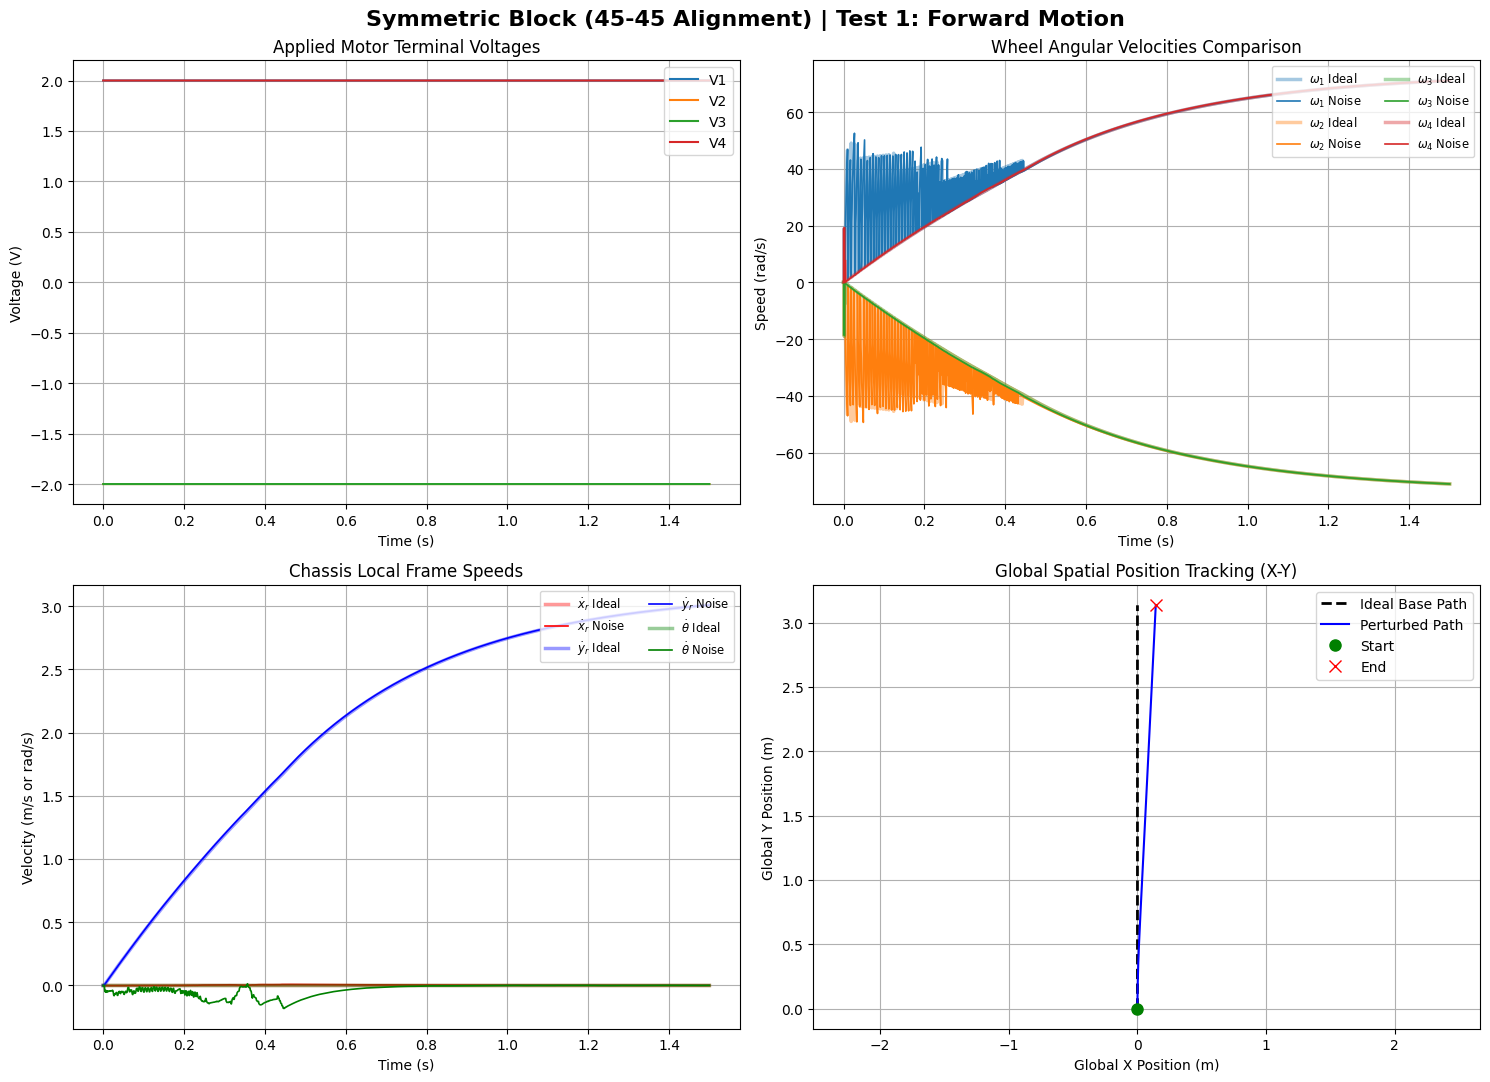

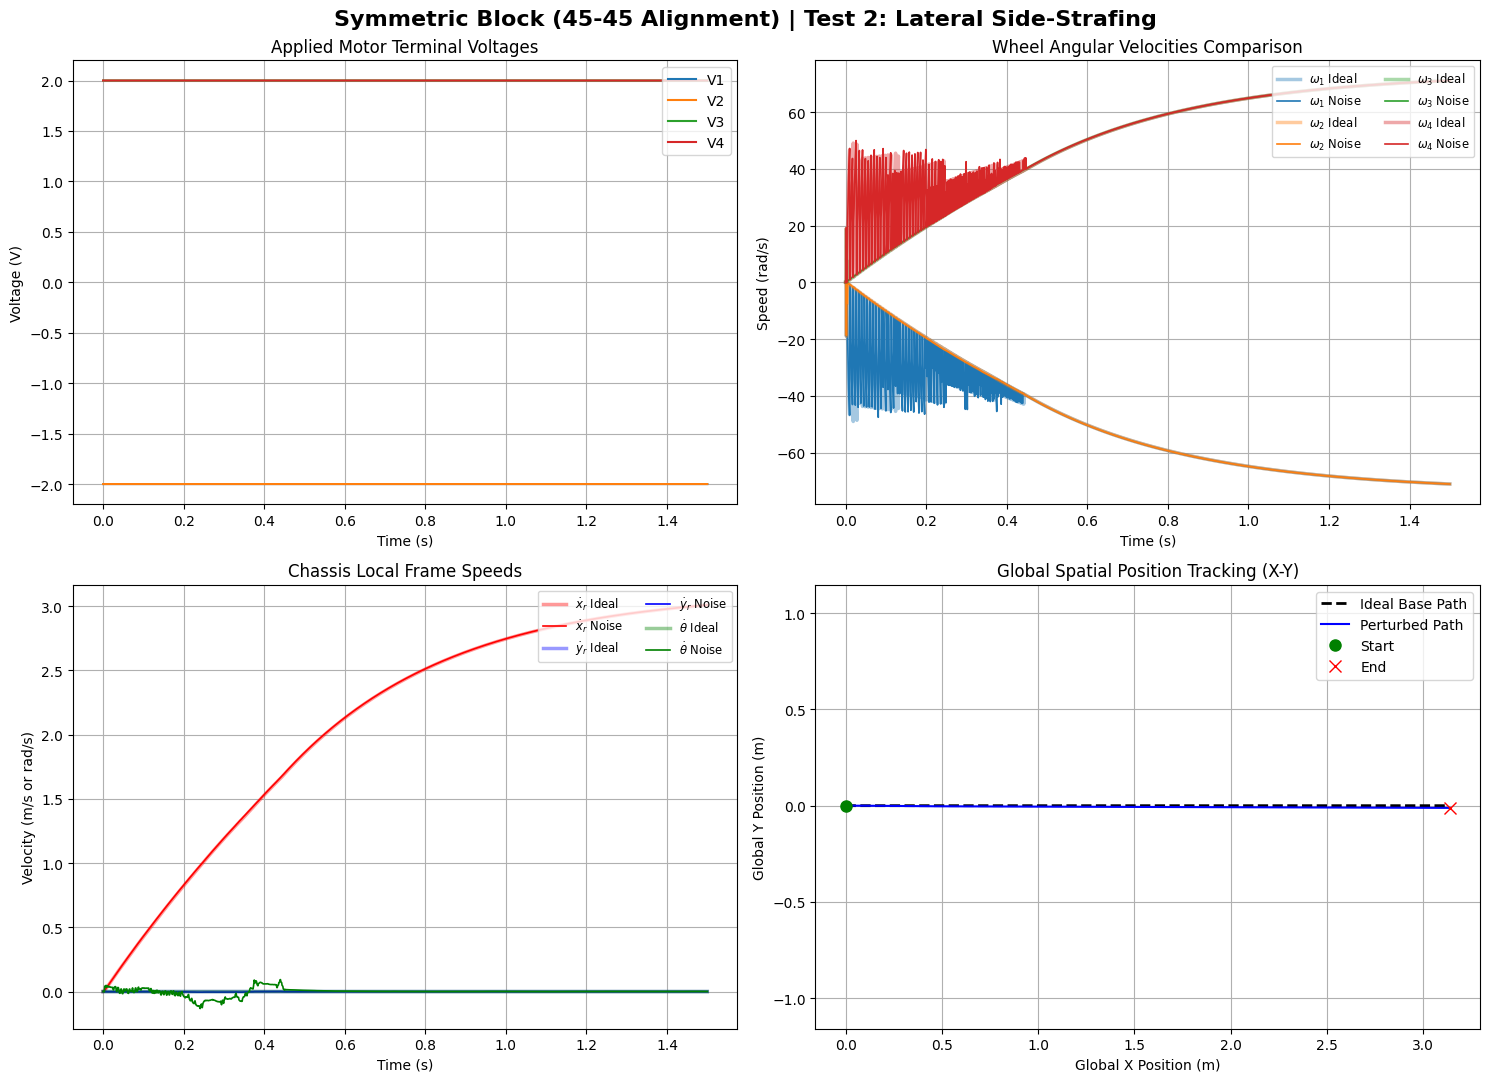

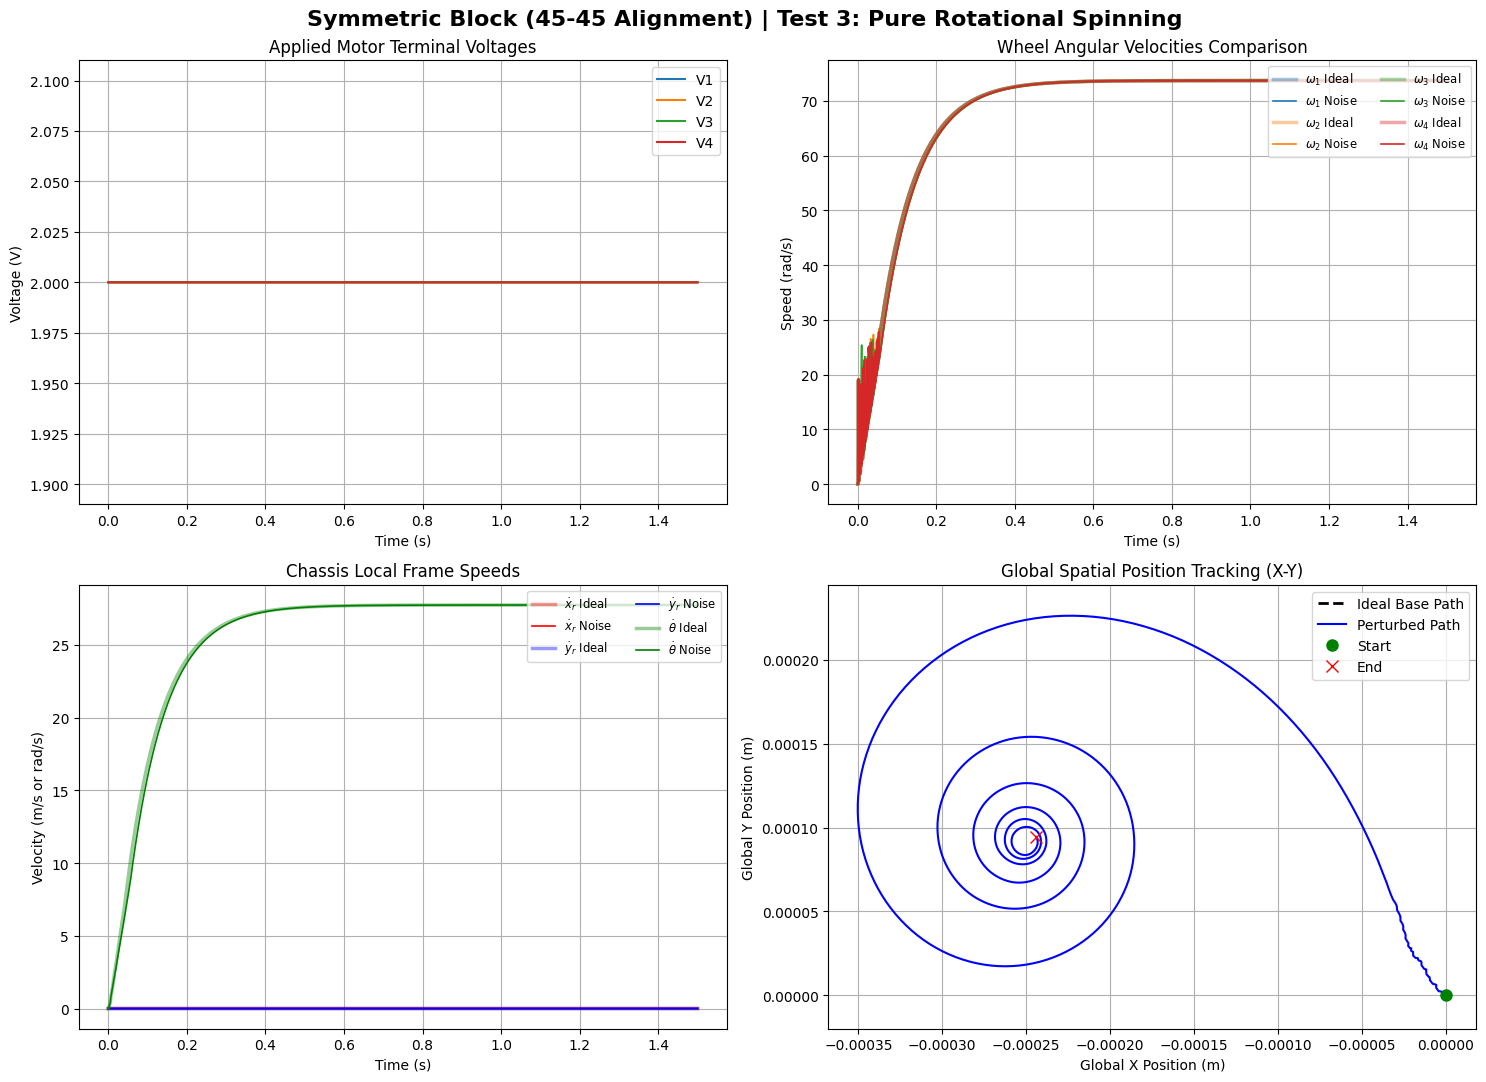

In [3]:
import numpy as np
import matplotlib.pyplot as plt

nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

t_end = 1.5  
dt = simulation_parameters['dt']
steps = int(t_end / dt)
t_vec = np.linspace(0, t_end, steps)

low_voltage = 2
maneuvers = [
    {"name": "Test 1: Forward Motion", "V": np.array([low_voltage, -low_voltage, -low_voltage, low_voltage])},
    {"name": "Test 2: Lateral Side-Strafing", "V": np.array([-low_voltage, -low_voltage, low_voltage, low_voltage])},
    {"name": "Test 3: Pure Rotational Spinning", "V": np.array([low_voltage, low_voltage, low_voltage, low_voltage])}
]

# REMOVED redundancy: line style 'ls' is isolated out of the style modifiers
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# CONFIGURATION CHANGE: FORCE SYMMETRIC 45-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(45.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Symmetric Block (45-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Isolated style configuration)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()


Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...


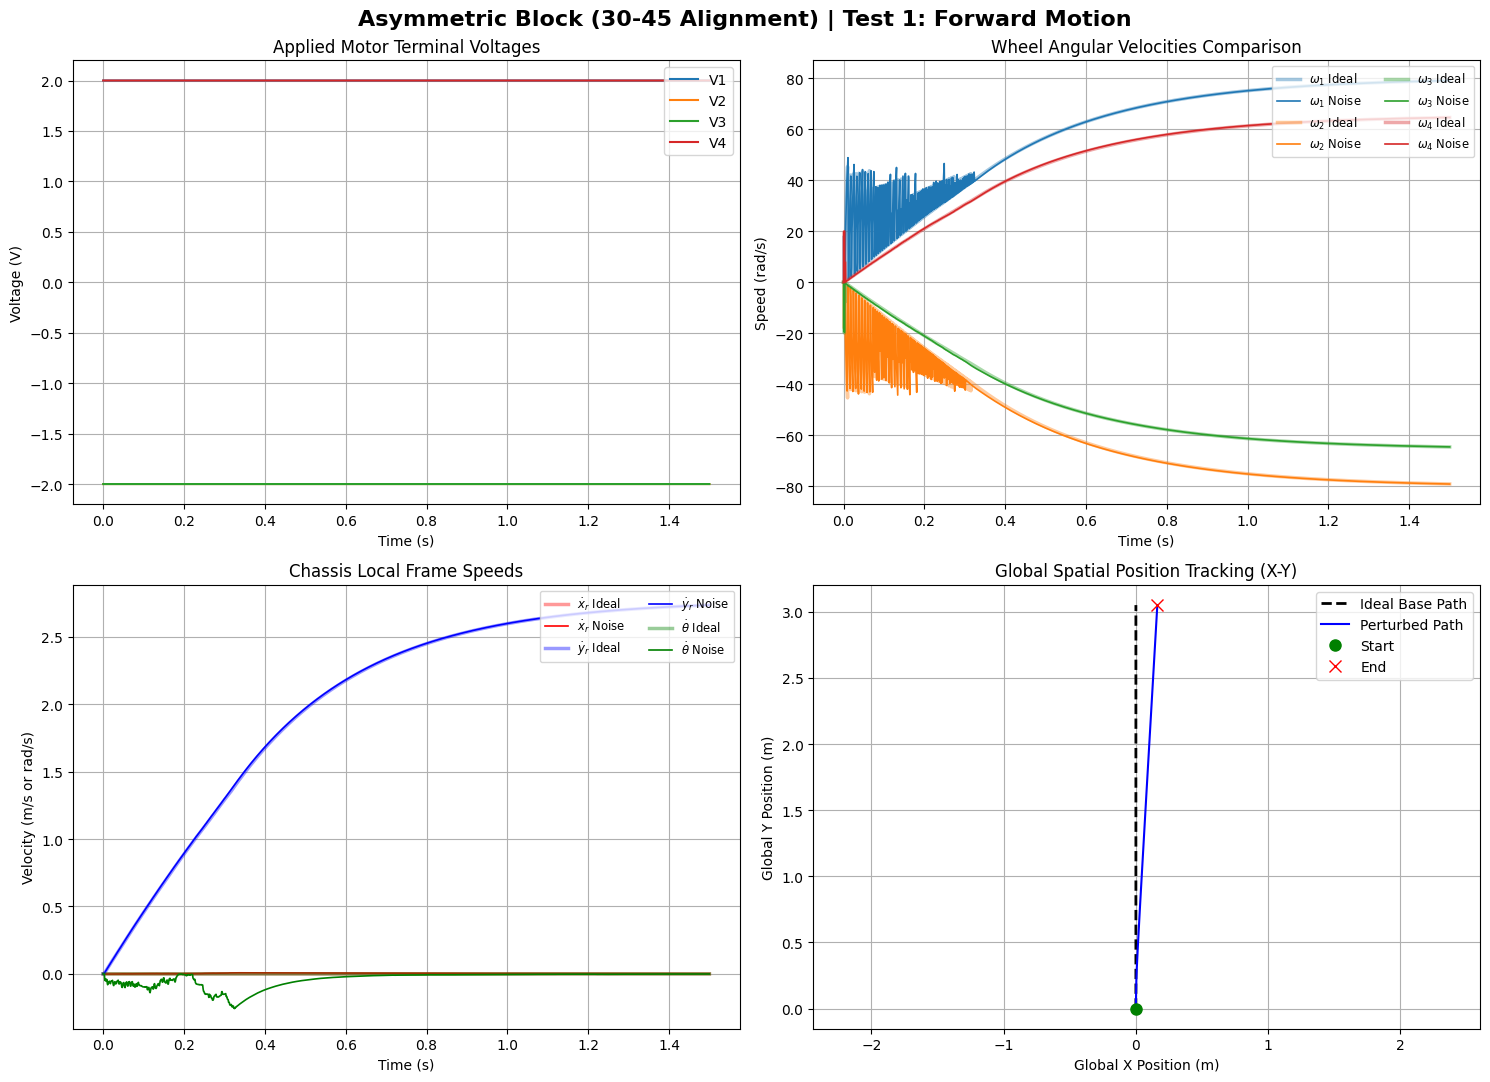

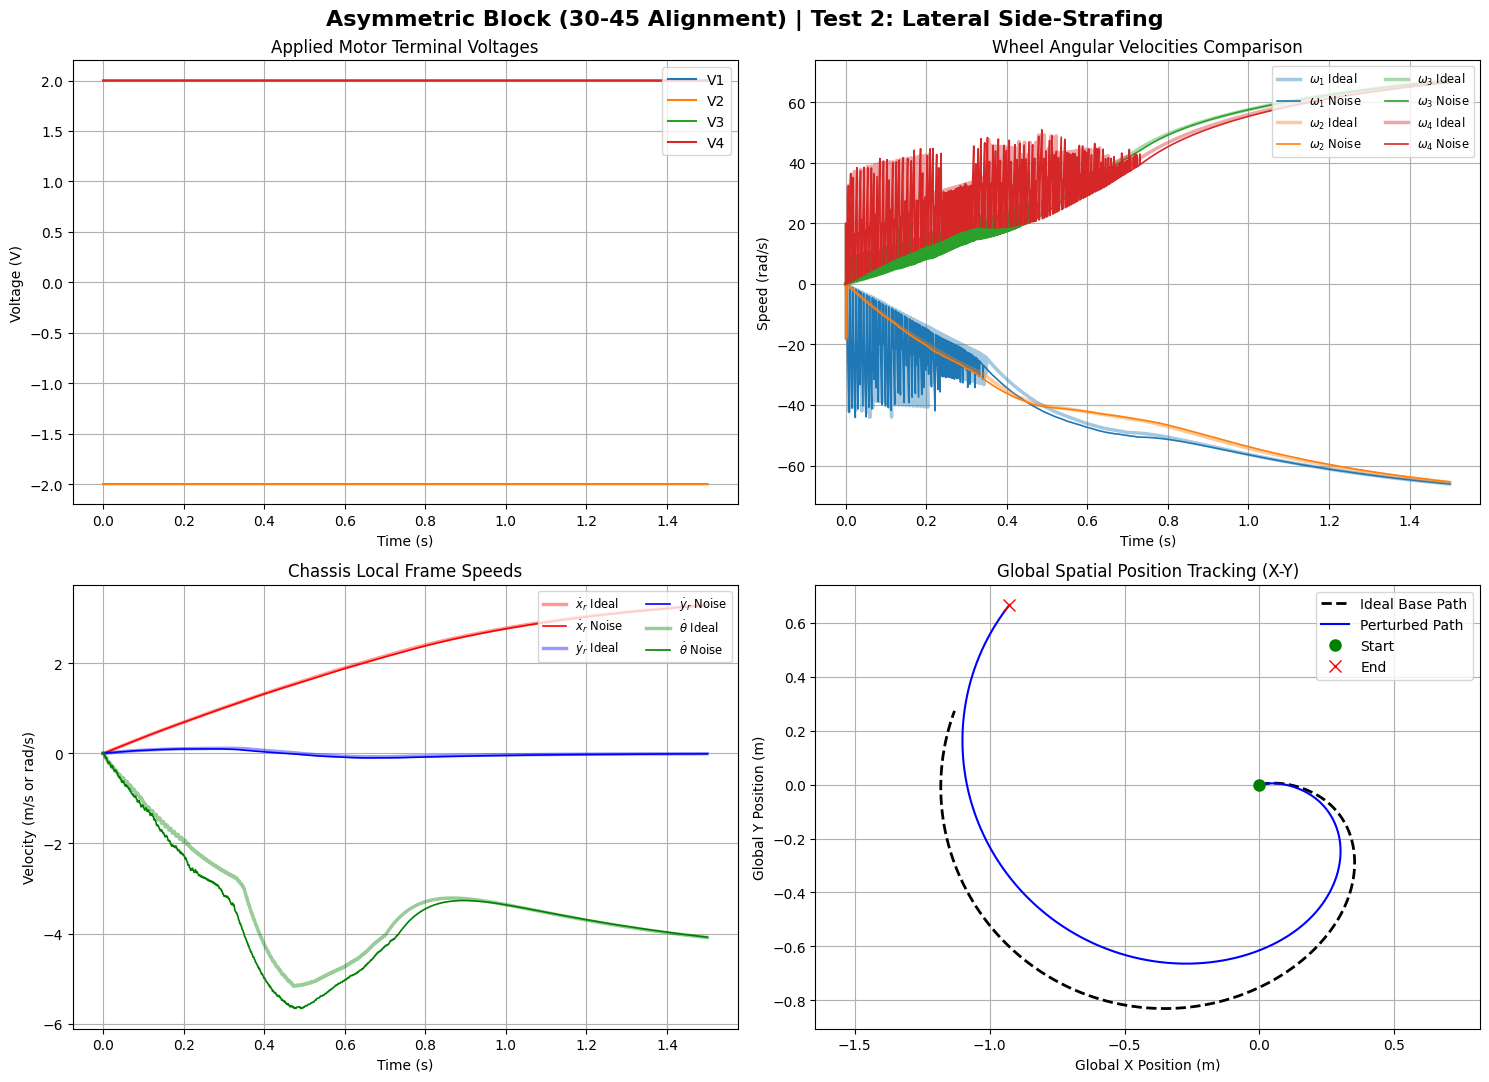

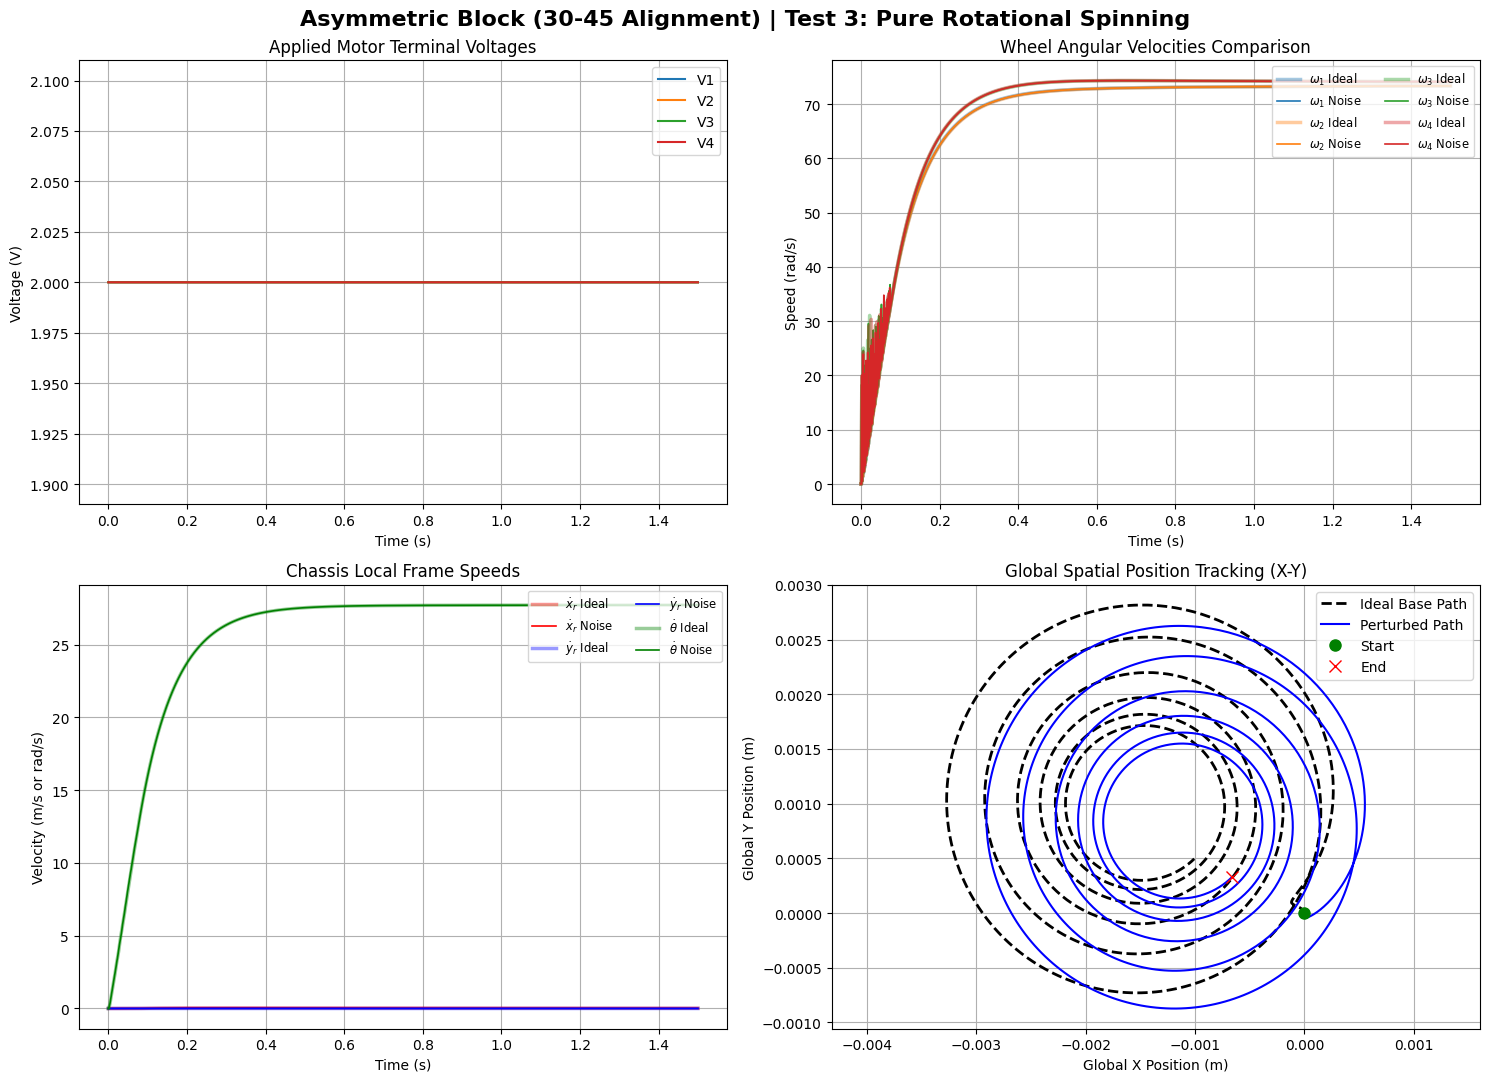

In [4]:
# CONFIGURATION CHANGE: REVERT TO ASYMMETRIC 30-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Block (30-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Line parameters isolated)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Safely restore baseline parameter noise variables back to configuration dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...


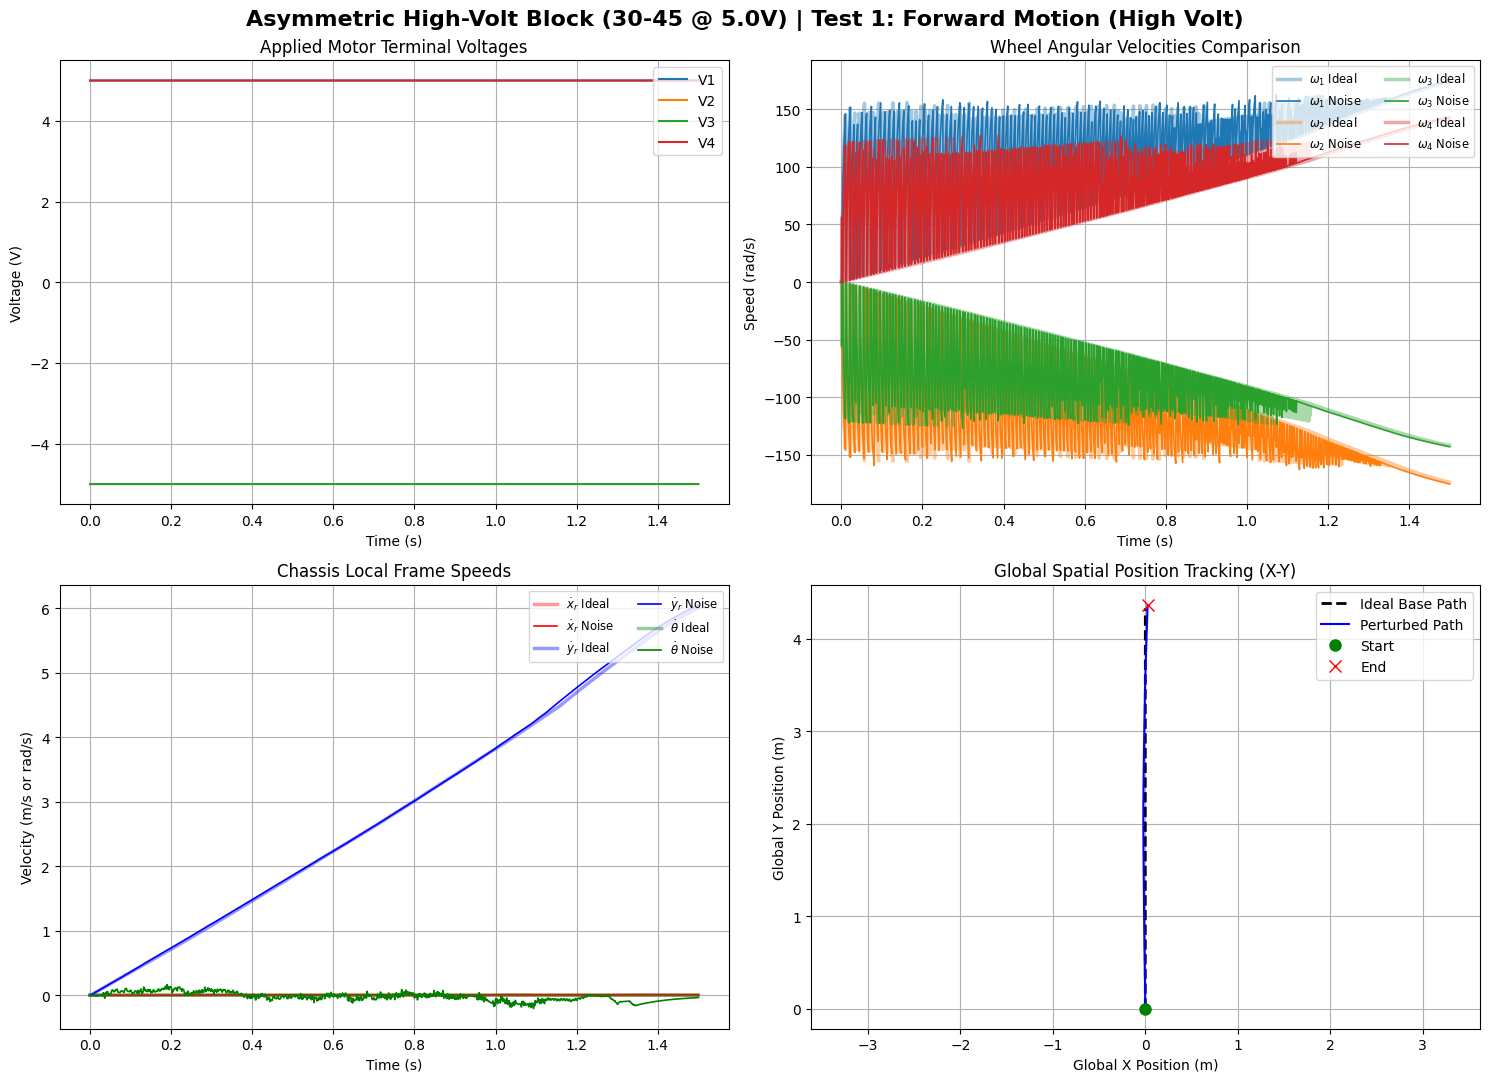

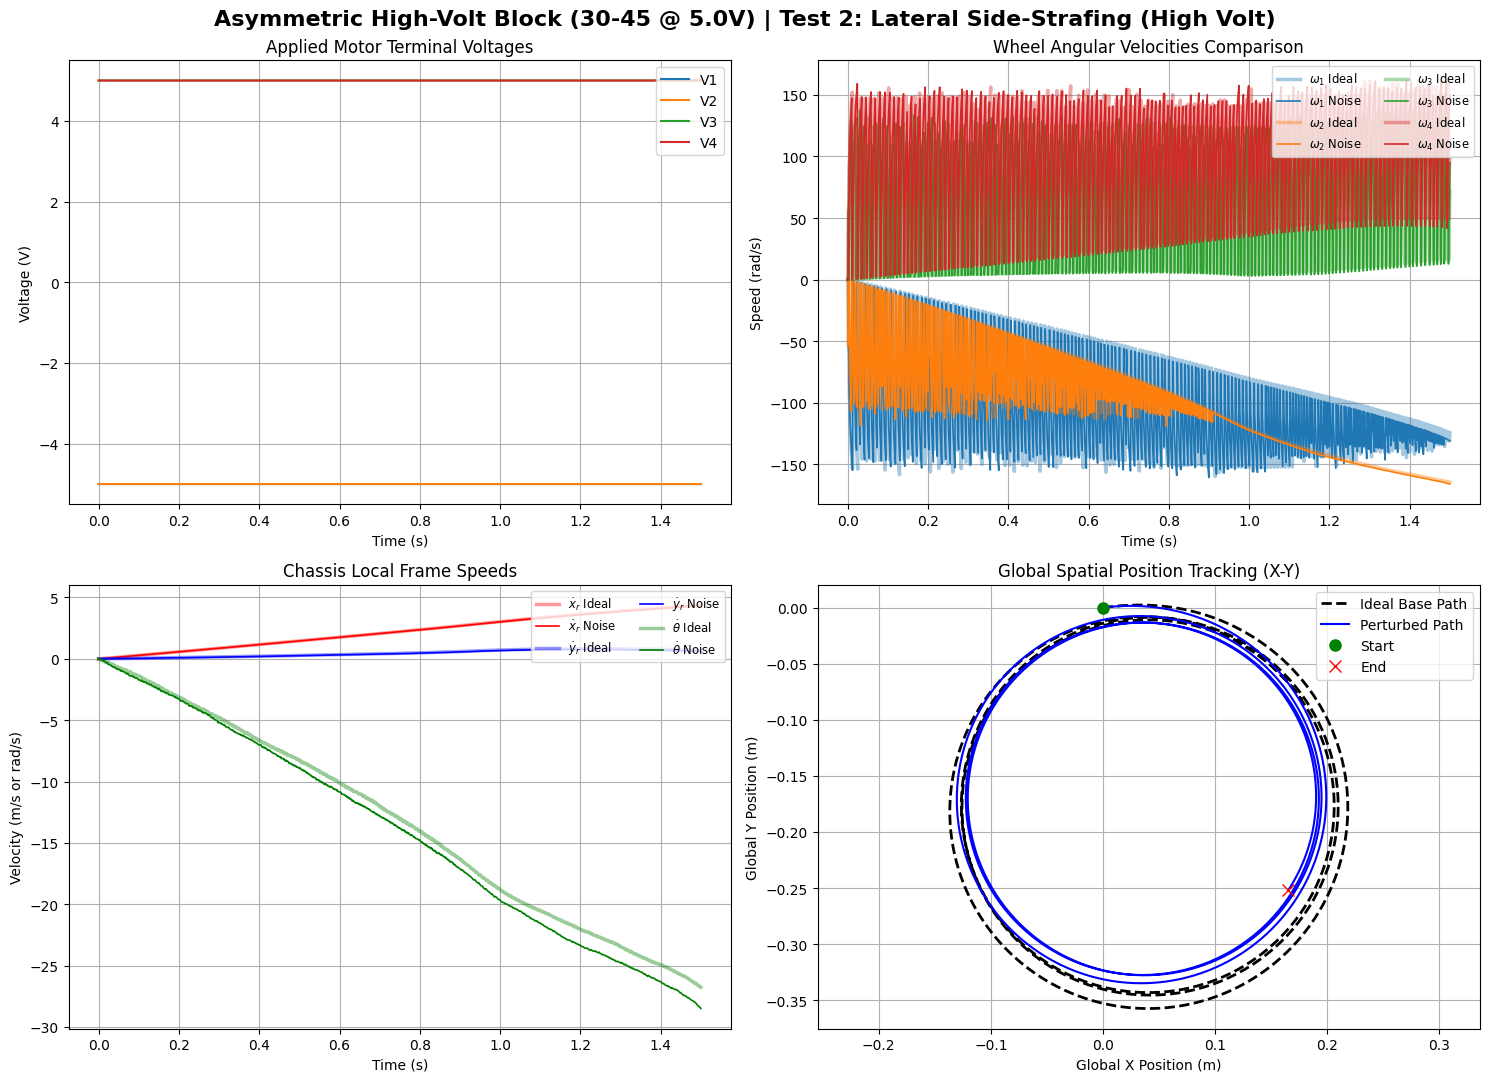

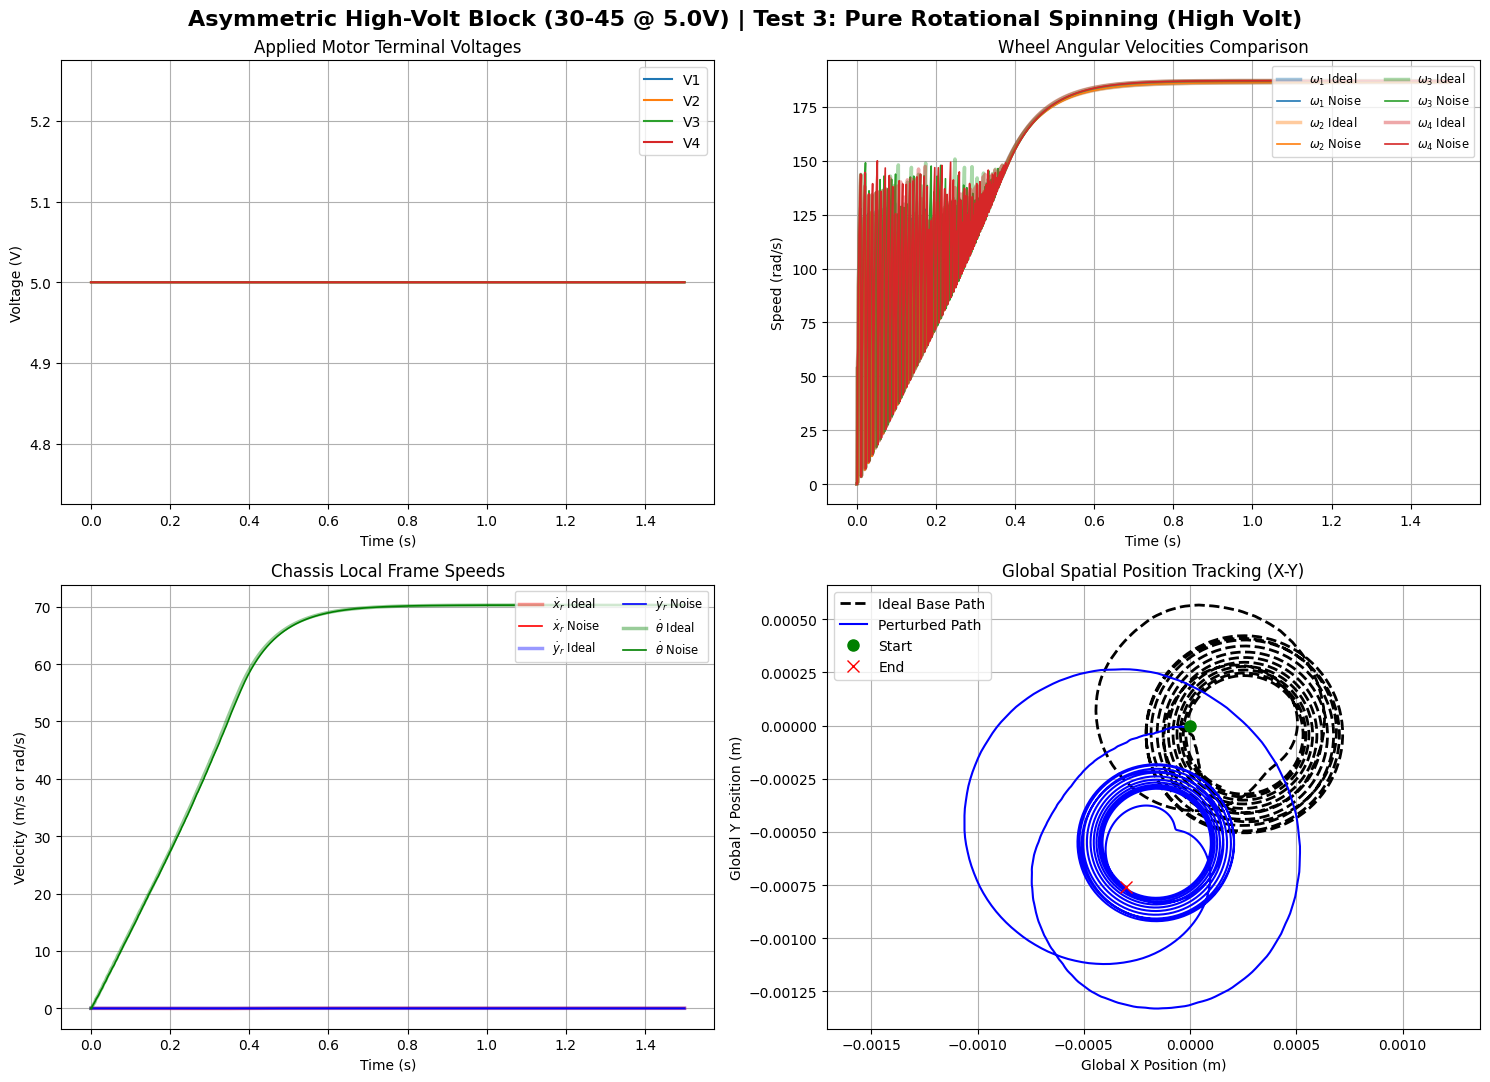

In [5]:
# =======================================================================
# CONFIGURATION CHANGE: KEEP ASYMMETRIC 30-45 DESIGN BUT BOOST TO 5.0V
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

bost_voltage = 5.0

# Define high-voltage directional maneuvers matching your verified sign choices
high_volt_maneuvers = [
    {"name": "Test 1: Forward Motion (High Volt)", "V": np.array([bost_voltage, -bost_voltage, -bost_voltage, bost_voltage])},
    {"name": "Test 2: Lateral Side-Strafing (High Volt)", "V": np.array([-bost_voltage, -bost_voltage, bost_voltage, bost_voltage])},
    {"name": "Test 3: Pure Rotational Spinning (High Volt)", "V": np.array([bost_voltage, bost_voltage, bost_voltage, bost_voltage])}
]

print("Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...")

for m in high_volt_maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        # Instantiate plant under custom asymmetric high-volt conditions (Seeded for reproducibility)
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric High-Volt Block (30-45 @ 5.0V) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Final safe restoration of baseline parameter noise variables back to dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


# 🧪 Multi-Stage Sequence Verification Testing

This section updates the verification routines to implement a **Multi-Stage Step Profile Timeline**. Instead of using simple, constant voltage step inputs, each directional test commands a dynamic voltage profile divided into three sequential 1.0-second stages. This structure explicitly evaluates your plant's transient response, high-velocity deceleration behavior, and rolling drag coasting decays.

### 🕹️ Chronological Stage Sequences
For each of the three directional axes, the simulation pushes a dynamic voltage vector $\mathbf{U}_k$ that varies depending on the current time step interval:
1.  **Stage 1: Positive Command Interval ($0.0\text{s} \le t < 1.0\text{s}$):** Motors receive a $+4.0$V scaled step command based on your hardware sign choices to accelerate the robot from a dead stop.
2.  **Stage 2: Negative/Reversal Interval ($1.0\text{s} \le t < 2.0\text{s}$):** Voltages instantly flip polarity to $-4.0$V. This forces the motor drives to act as active plug-brakes, fighting the massive momentum of the chassis, decelerating it to a stop, and reversing its trajectory.
3.  **Stage 3: Zero/Coasting Interval ($2.0\text{s} \le t \le 3.0\text{s}$):** Voltage commands drop flat to $0.0$V. The robot's electrical drive cuts out entirely, forcing the vehicle to coast to a complete stop purely by bleeding kinetic energy through the wheels' internal parasitic rolling resistance ($C_{rr}$).

### 🗺️ Multi-Stage Directional Key
The three tests map these positive/negative/zero step magnitudes to the following hardware-verified wheel groups:
*   **Test 1: Forward/Backward Sequence:** Drives straight ahead along local $+Y_r$, plugs the motors into reverse to fly backward along $-Y_r$, and then cuts voltage to zero.
*   **Test 2: Side-to-Side Sequence:** Strafes directly left along local $-X_r$, reverses direction to strafe back right along $+X_r$, and then drops into a dead coast.
*   **Test 3: CCW/CW Rotation Sequence:** Spins the entire robot counter-clockwise ($+\theta$) around its Center of Mass, actively reverses momentum into a clockwise spin ($-\theta$), and then coasts down.

### 🔄 Comparative Telemetry Observations
By stringing these phases back-to-back, the generated 2x2 graphics grids highlight critical non-linear coupling effects across the **Ideal vs. Disturbed** runs:
*   **Transient Speed Chattering:** At the $t = 1.0$s mark, when the voltage violently snaps from positive to negative, the wheels experience a massive sudden torque unbalance while the vehicle chassis is still moving forward. This breaks floor adhesion and causes **prolonged, high-frequency wheel speed spikes** on the disturbed plots as wheels lose grip and spin out independently.
*   **Deceleration and Coasting Curves:** Subplot 3 visualizes the real-world back-EMF damping slopes during reverse braking, alongside the long exponential velocity decay during the final unpowered coasting interval.
*   **Trajectory Drift Accumulation:** Subplot 4 maps the absolute spatial motion. It marks exactly where the direction switches happen (`Switch to Neg` and `Switch to Zero`), illustrating how uneven wheel spinouts during violent direction changes heavily amplify open-loop navigation drift away from the baseline ideal path.


Executing Profile Tests under Asymmetric 30-45 Geometry...


C:\Users\Henry\AppData\Local\Temp\ipykernel_9524\2171815845.py:106: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
C:\Users\Henry\AppData\Local\Temp\ipykernel_9524\2171815845.py:107: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
C:\Users\Henry\AppData\Local\Temp\ipykernel_9524\2171815845.py:108: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal

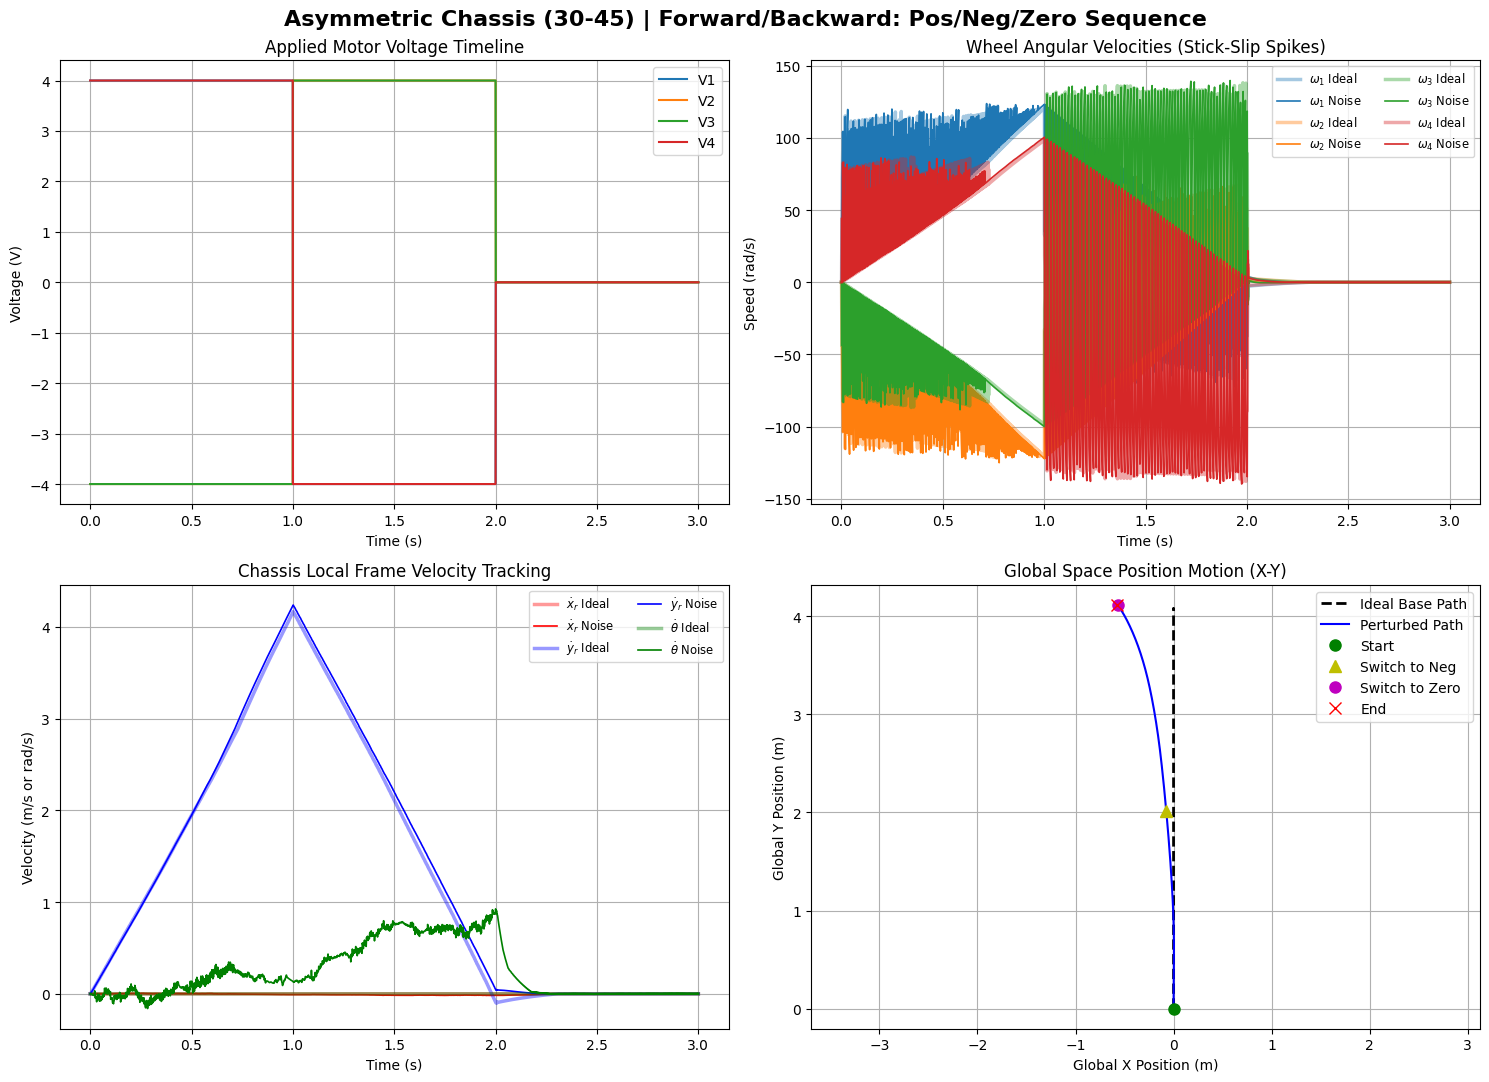

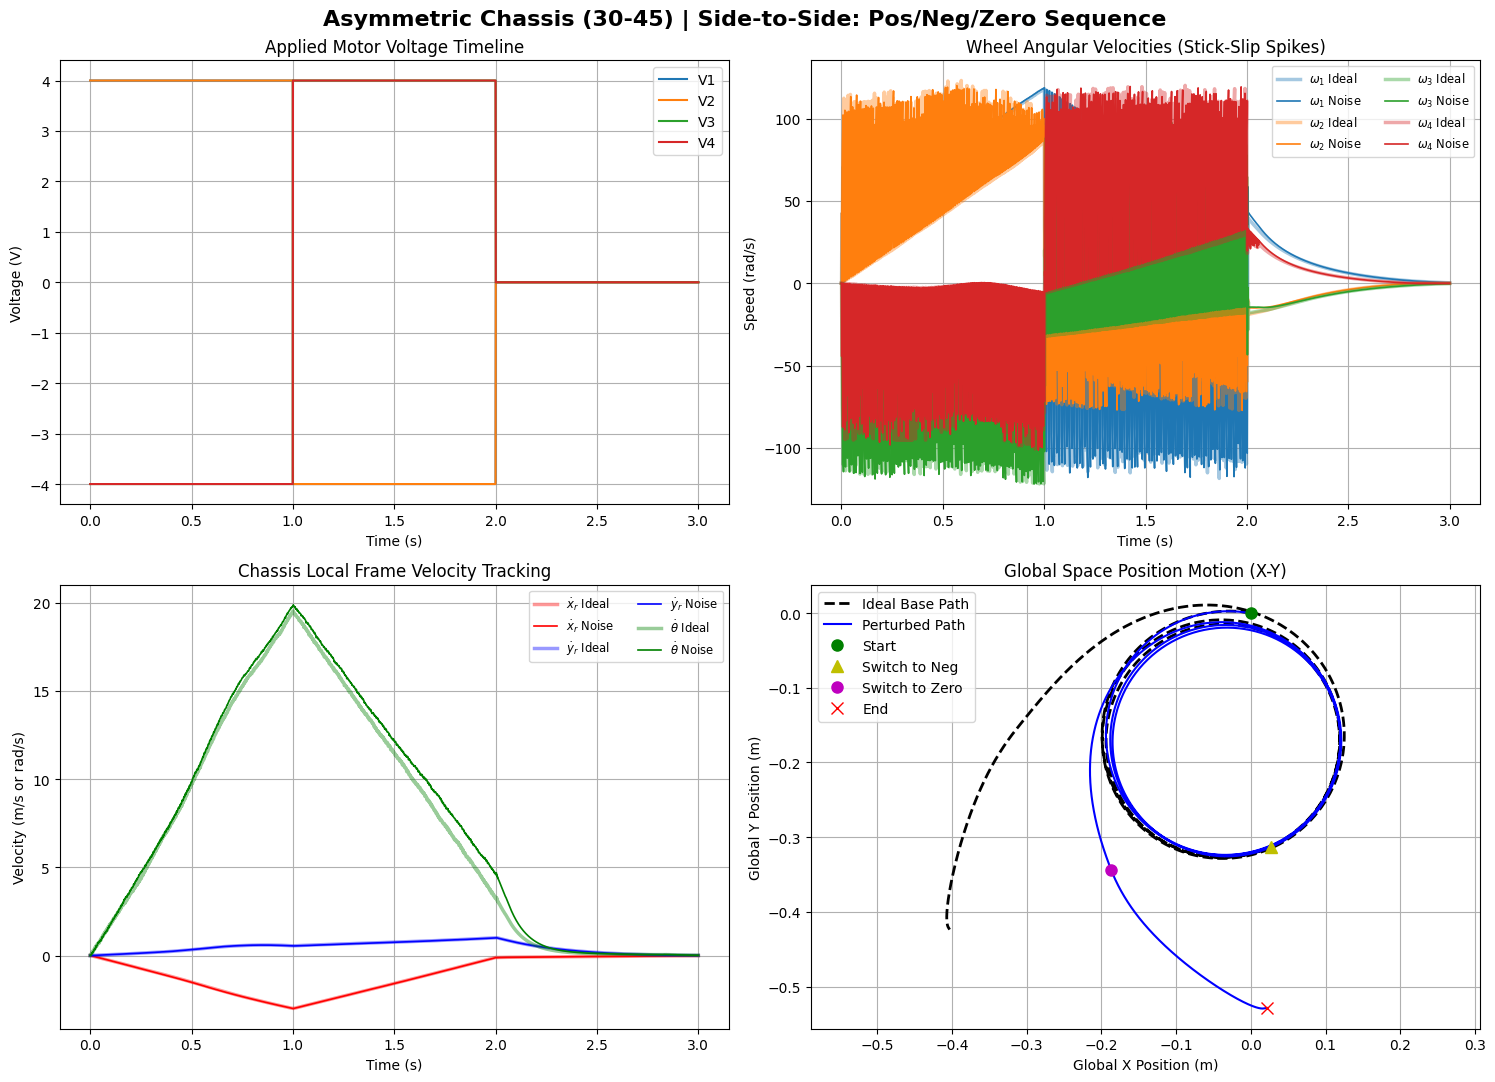

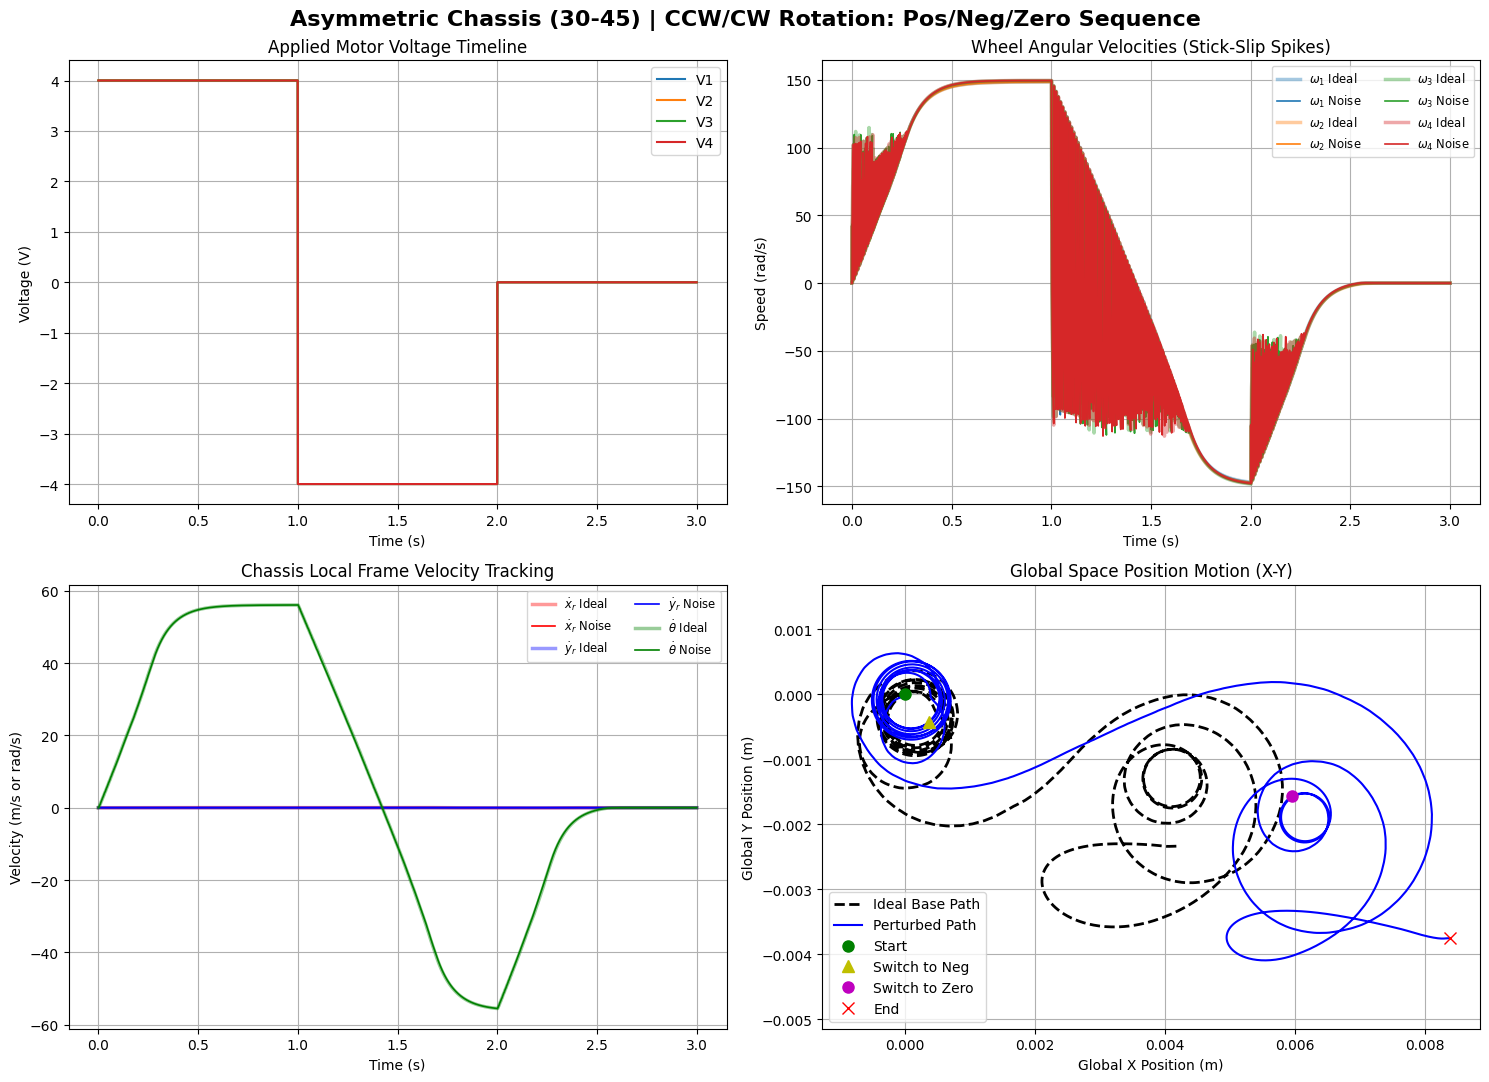

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Save your configured noise parameters to toggle the passes cleanly
nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

# Define a 3.0 second timeline split into three distinct 1.0s intervals
t_stage = 1.0
dt = simulation_parameters['dt']
steps_per_stage = int(t_stage / dt)
total_steps = steps_per_stage * 3
t_vec = np.linspace(0, t_stage * 3, total_steps)

# Helper function to dynamically generate the voltage vector at any given step index k
def get_profile_voltage(test_type, step_idx, steps_per_stage):
    # Determine which chronological stage we are currently executing
    if step_idx < steps_per_stage:
        stage = "Positive"
        mag = 4.0
    elif step_idx < 2 * steps_per_stage:
        stage = "Negative"
        mag = -4.0
    else:
        stage = "Zero"
        mag = 0.0
        
    # Apply your verified hardware directional sign combinations scaled by stage magnitude
    if test_type == "Forward/Backward":
        return np.array([mag, -mag, -mag, mag])
    elif test_type == "Side-to-Side":
        return np.array([mag, mag, -mag, -mag])
    elif test_type == "CCW/CW Rotation":
        return np.array([mag, mag, mag, mag])
    return np.zeros(4)

# Define our three complex multi-stage test scenarios
test_scenarios = ["Forward/Backward", "Side-to-Side", "CCW/CW Rotation"]

# Plotting configuration styles
style_ideal = {'ls': '-', 'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'ls': '-', 'alpha': 1.0, 'lw': 1.2}  

# =======================================================================
# STRUCTURAL RUN 1: ASYMMETRIC 30-45 CONFIGURATION WITH PROFILE MANEUVERS
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Profile Tests under Asymmetric 30-45 Geometry...")

for test_name in test_scenarios:
    runs_data = {}
    
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        # Step through the full 3.0 second timeline
        for k in range(total_steps):
            V_cmd = get_profile_voltage(test_name, k, steps_per_stage)
            
            v_in_hist.append(V_cmd.copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            
            state, T_load, S_status = robot_plant.step(state, V_cmd)
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    # -------------------------------------------------------------------
    # GENERATE 2x2 GRAPHS FOR COMPLEX PROFILE COUPLING
    # -------------------------------------------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Chassis (30-45) | {test_name}: Pos/Neg/Zero Sequence", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Profiles (Now showing step changes over time)
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Voltage Timeline")
    axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds showing spikes during aggressive direction switches
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities (Stick-Slip Spikes)"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Velocities showing Braking/Deceleration Curves
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Velocity Tracking"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane showing bidirectional path trace
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][steps_per_stage, 0], noisy["pos_global"][steps_per_stage, 1], 'y^', markersize=8, label='Switch to Neg')
    axs[1, 1].plot(noisy["pos_global"][2*steps_per_stage, 0], noisy["pos_global"][2*steps_per_stage, 1], 'mo', markersize=8, label='Switch to Zero')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Space Position Motion (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Restore baseline parameters securely
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu
